# Predicción de Diabetes Mediante Técnicas de Minería de Datos Aplicadas a Indicadores de Salud

**Proyecto de aula – Avance 3 (Corte 3): revisión del modelo, optimización y despliegue en Streamlit**
**Universidad de la Costa (CUC) – Departamento de Ciencias de la Computación y Electrónica – Ingeniería de Sistemas**
**Curso:** Minería de Datos · **Profesor:** José Escorcia Gutiérrez

**Integrantes:**
- Alison Lara Correa
- Roger Bolaño Truyol
- Valeri Alvarez Blanco

**Tipo de proyecto:** Clasificación supervisada (binaria).

**Pregunta de investigación:** ¿Es posible predecir si una paciente presenta diabetes a partir de indicadores clínicos y demográficos no invasivos (glucosa, presión arterial, IMC, insulina, edad, antecedentes familiares, etc.), y qué modelo de clasificación ofrece el mejor equilibrio entre detectar a las pacientes diabéticas (recall) y evitar falsas alarmas (precision)?

**Dataset:** Pima Indians Diabetes Dataset (National Institute of Diabetes and Digestive and Kidney Diseases). Fuente de descarga: https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.csv (referencia equivalente en Kaggle: https://www.kaggle.com/datasets/amineipad/diabetes-dataset). 768 registros, 9 columnas.

**Variable objetivo:** `Outcome` (1 = diabetes, 0 = no diabetes).

Las secciones 1 a 8 corresponden al primer avance y las secciones 9 a 14 al segundo avance; se conservan con las salidas re‑ejecutadas. Las secciones 15 en adelante corresponden al tercer corte: revisión del rendimiento, optimización del modelo y preparación del pipeline para la aplicación en Streamlit.

## 0. Cambios frente al primer avance

| Aspecto | Primer avance | Segundo avance | Justificación |
|---|---|---|---|
| Dataset, pregunta y variable objetivo | Pima Indians Diabetes, `Outcome` | Sin cambios | El problema y los datos siguen siendo adecuados. |
| Imputación de ceros no válidos | Mediana calculada sobre **todo** el dataset | Mediana calculada **solo con el conjunto de entrenamiento**, dentro de un `Pipeline` | Imputar con todo el dataset filtra información del conjunto de prueba hacia el entrenamiento (fuga de información). La limpieza del avance 1 se mantiene para el EDA descriptivo, pero no se usa para entrenar. |
| Variable `outcome_label` | Creada para gráficas | Se usa solo en el EDA; se excluye de las predictoras | Es una copia textual del objetivo; incluirla sería fuga de información. |
| Outliers | Solo se reportaron | Se conservan (decisión justificada en la sección 9) | Son valores clínicamente posibles. |

## 1. Descripción del Dataset (2.1)

- **Nombre del dataset:** Pima Indians Diabetes Dataset
- **Fuente / enlace de descarga:** Dataset de referencia sugerido para el proyecto: [Diabetes Dataset - Kaggle](https://www.kaggle.com/datasets/amineipad/diabetes-dataset). Para este avance se trabajó con la versión pública equivalente del *National Institute of Diabetes and Digestive and Kidney Diseases*, distribuida en el repositorio de datasets de referencia de Jason Brownlee: https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.csv
- **Descripción del contenido:** El dataset contiene información clínica y demográfica de mujeres de al menos 21 años, de ascendencia Pima (Arizona, EE. UU.), utilizada históricamente para predecir la presencia de diabetes tipo 2 a partir de indicadores médicos no invasivos (glucosa, presión arterial, índice de masa corporal, número de embarazos, entre otros).
- **Número de filas y columnas:** 768 filas (pacientes) y 9 columnas (8 variables predictoras + 1 variable objetivo).
- **Propósito general del dataset:** Servir como base para construir modelos de clasificación que permitan predecir el riesgo de diabetes en una paciente a partir de variables clínicas fácilmente medibles, apoyando la detección temprana y la priorización de exámenes complementarios.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)

# Carga del dataset
df = pd.read_csv("diabetes_dataset.csv")
print(f"Dimensiones del dataset: {df.shape[0]} filas x {df.shape[1]} columnas")
df.head()

Dimensiones del dataset: 768 filas x 9 columnas


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 2. Descripción de Variables (2.2)

| Variable | Descripción |
|---|---|
| `Pregnancies` | Número de embarazos que ha tenido la paciente |
| `Glucose` | Concentración de glucosa en plasma a las 2 horas de una prueba de tolerancia oral (mg/dL) |
| `BloodPressure` | Presión arterial diastólica (mm Hg) |
| `SkinThickness` | Espesor del pliegue cutáneo del tríceps (mm) |
| `Insulin` | Insulina sérica a las 2 horas (mu U/ml) |
| `BMI` | Índice de masa corporal (peso en kg / (altura en m)^2) |
| `DiabetesPedigreeFunction` | Puntaje que estima la probabilidad de diabetes según antecedentes familiares |
| `Age` | Edad de la paciente (años) |
| `Outcome` | **Variable objetivo (target):** 1 = presenta diabetes, 0 = no presenta diabetes |

**Tipo de proyecto:** Clasificación binaria. La variable objetivo identificada es `Outcome`. El resto de las variables (`Pregnancies`, `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, `BMI`, `DiabetesPedigreeFunction`, `Age`) son las variables predictoras que se usarán en fases posteriores para entrenar los modelos de clasificación.

## 3. Carga de Datos y Exploración Inicial (2.3)

In [2]:
# Tamaño del dataset
print("Forma del dataset (filas, columnas):", df.shape)

Forma del dataset (filas, columnas): (768, 9)


In [3]:
# Tipos de datos
df.dtypes

Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

In [4]:
# Estadísticas descriptivas generales
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [5]:
# Identificación de variables numéricas y categóricas
numericas = df.select_dtypes(include=[np.number]).columns.tolist()
categoricas = df.select_dtypes(exclude=[np.number]).columns.tolist()

print("Variables numéricas:", numericas)
print("Variables categóricas:", categoricas if categoricas else "No se identificaron variables categóricas explícitas.")
print("\nNota: 'Outcome' es numérica (0/1) pero funciona conceptualmente como variable categórica binaria (target).")

Variables numéricas: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']
Variables categóricas: No se identificaron variables categóricas explícitas.

Nota: 'Outcome' es numérica (0/1) pero funciona conceptualmente como variable categórica binaria (target).


## 4. Diagnóstico Inicial de Calidad de Datos (2.4)

Se revisan valores faltantes explícitos, duplicados, variables mal codificadas, datos inconsistentes y posibles outliers.

In [6]:
# Valores faltantes explícitos (NaN)
print("Valores nulos por columna:")
print(df.isnull().sum())

Valores nulos por columna:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [7]:
# Registros duplicados
duplicados = df.duplicated().sum()
print(f"Número de registros duplicados: {duplicados}")

Número de registros duplicados: 0


In [8]:
# Valores en 0 en columnas donde 0 no es fisiológicamente válido
# (esto revela 'missing values disfrazados' de ceros, un problema común de este dataset)
cols_check = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
ceros = (df[cols_check] == 0).sum()
print("Cantidad de valores en 0 (probablemente datos faltantes codificados como 0):")
print(ceros)
print("\nPorcentaje sobre el total de registros:")
print((ceros / len(df) * 100).round(2))

Cantidad de valores en 0 (probablemente datos faltantes codificados como 0):
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Porcentaje sobre el total de registros:
Glucose           0.65
BloodPressure     4.56
SkinThickness    29.56
Insulin          48.70
BMI               1.43
dtype: float64


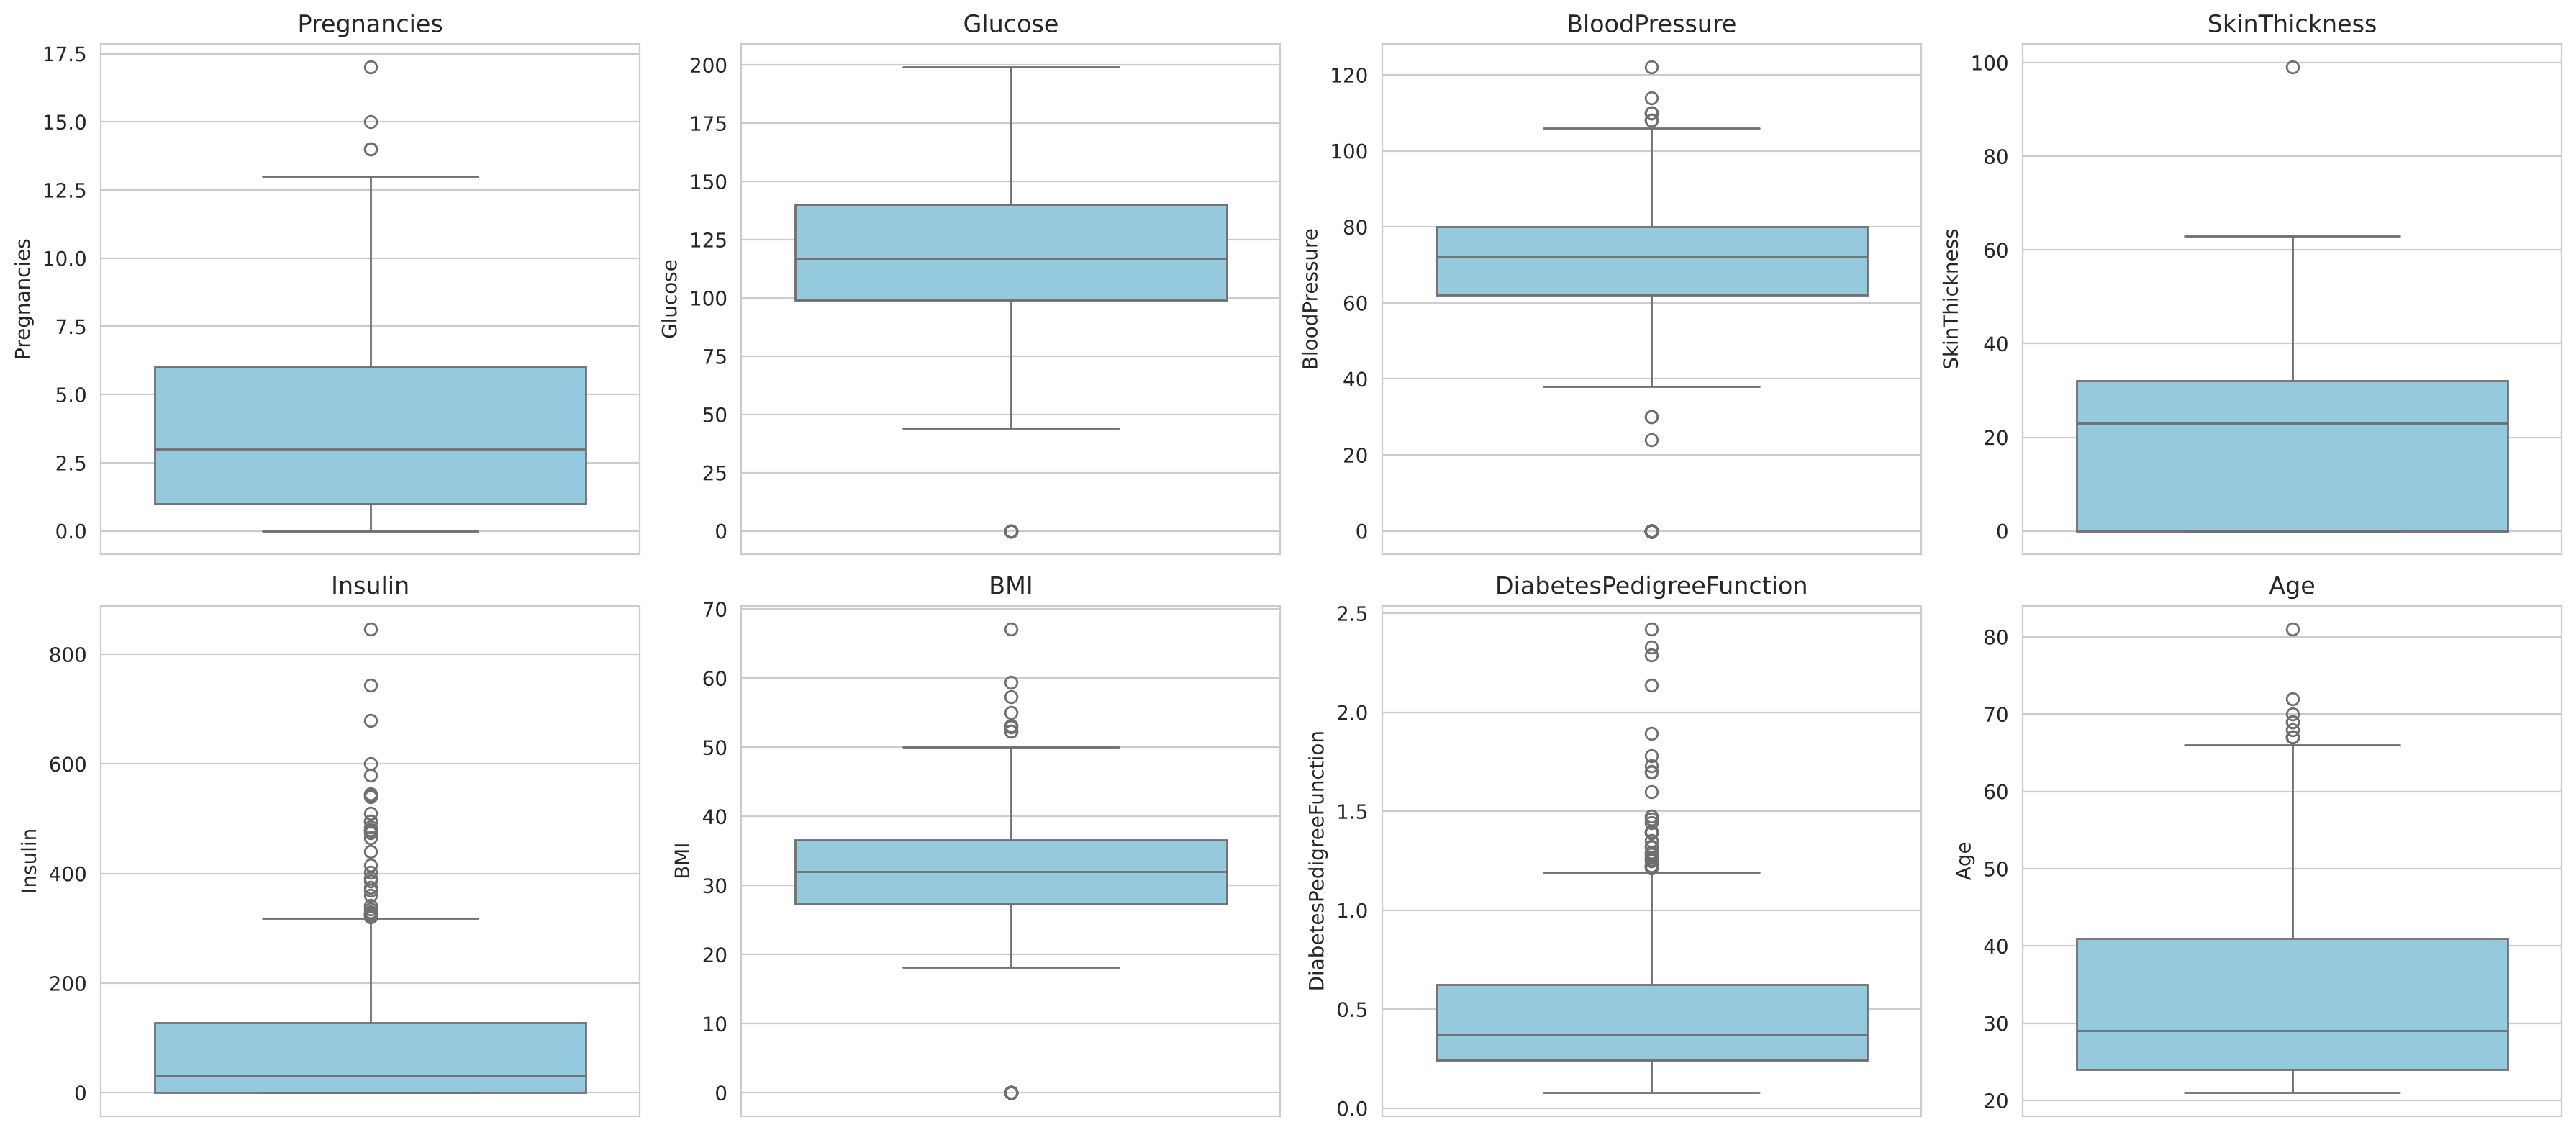

In [9]:
# Revisión de posibles outliers con boxplots
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()
for i, col in enumerate(numericas[:-1]):  # excluye Outcome
    sns.boxplot(y=df[col], ax=axes[i], color="skyblue")
    axes[i].set_title(col)
plt.tight_layout()
plt.savefig("outliers_boxplots.png", dpi=100)
plt.show()

**Diagnóstico encontrado:**
- No hay valores `NaN` explícitos en el dataset.
- No se encontraron registros duplicados.
- Sin embargo, columnas como `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin` y `BMI` presentan una cantidad considerable de valores en **0**, lo cual es clínicamente imposible (una persona viva no puede tener presión arterial o glucosa igual a 0). Esto indica **datos faltantes codificados como 0**, un problema de calidad que debe corregirse.
- `Insulin` y `SkinThickness` son las variables con mayor proporción de estos "ceros ocultos", y los boxplots muestran además la presencia de **outliers** (valores extremos) en `Insulin`, `DiabetesPedigreeFunction` y `Pregnancies`.
- No se identifican columnas de bajo valor analítico que deban eliminarse en esta primera fase; todas las variables tienen sustento clínico para el problema de clasificación.

## 5. Limpieza Inicial de Datos en Python (2.5)

In [10]:
# 1. Copia de trabajo para conservar el dataset original
df_clean = df.copy()

# 2. Corrección de nombres de columnas (estandarización a snake_case)
df_clean.columns = [c.strip().lower() for c in df_clean.columns]
df_clean.rename(columns={"diabetespedigreefunction": "diabetes_pedigree_function"}, inplace=True)
print(df_clean.columns.tolist())

['pregnancies', 'glucose', 'bloodpressure', 'skinthickness', 'insulin', 'bmi', 'diabetes_pedigree_function', 'age', 'outcome']


In [11]:
# 3. Tratamiento de valores faltantes (ceros disfrazados)
# Se reemplazan los ceros no válidos por NaN y luego se imputan con la mediana de cada variable
cols_fix = ["glucose", "bloodpressure", "skinthickness", "insulin", "bmi"]

for col in cols_fix:
    df_clean[col] = df_clean[col].replace(0, np.nan)

print("Valores faltantes tras marcar los ceros como NaN:")
print(df_clean[cols_fix].isnull().sum())

Valores faltantes tras marcar los ceros como NaN:
glucose            5
bloodpressure     35
skinthickness    227
insulin          374
bmi               11
dtype: int64


In [12]:
# Imputación con la mediana (más robusta que la media ante outliers)
for col in cols_fix:
    mediana = df_clean[col].median()
    df_clean[col] = df_clean[col].fillna(mediana)

print("Valores faltantes después de la imputación:")
print(df_clean[cols_fix].isnull().sum())

Valores faltantes después de la imputación:
glucose          0
bloodpressure    0
skinthickness    0
insulin          0
bmi              0
dtype: int64


In [13]:
# 4. Eliminación de duplicados (verificación, aunque no se encontraron en el diagnóstico)
antes = df_clean.shape[0]
df_clean = df_clean.drop_duplicates()
print(f"Registros antes: {antes} | Registros después de eliminar duplicados: {df_clean.shape[0]}")

Registros antes: 768 | Registros después de eliminar duplicados: 768


In [14]:
# 5. Conversión de tipos de datos
df_clean["outcome"] = df_clean["outcome"].astype("category")
df_clean["pregnancies"] = df_clean["pregnancies"].astype(int)
print(df_clean.dtypes)

pregnancies                      int64
glucose                        float64
bloodpressure                  float64
skinthickness                  float64
insulin                        float64
bmi                            float64
diabetes_pedigree_function     float64
age                              int64
outcome                       category
dtype: object


In [15]:
# 6. Revisión de outliers mediante el método del rango intercuartílico (IQR)
# Solo se reporta aquí; el tratamiento definitivo (winsorizing, transformación, etc.)
# se abordará con mayor profundidad en el siguiente periodo académico.
def detectar_outliers_iqr(serie):
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1
    lim_inf = q1 - 1.5 * iqr
    lim_sup = q3 + 1.5 * iqr
    return ((serie < lim_inf) | (serie > lim_sup)).sum()

for col in ["glucose", "bloodpressure", "bmi", "insulin", "diabetes_pedigree_function", "age"]:
    n_out = detectar_outliers_iqr(df_clean[col])
    print(f"{col}: {n_out} posibles outliers (método IQR)")

glucose: 0 posibles outliers (método IQR)
bloodpressure: 14 posibles outliers (método IQR)
bmi: 8 posibles outliers (método IQR)
insulin: 346 posibles outliers (método IQR)
diabetes_pedigree_function: 29 posibles outliers (método IQR)
age: 9 posibles outliers (método IQR)


In [16]:
# 7. Estandarización de la variable categórica objetivo (etiquetas legibles para el EDA)
df_clean["outcome_label"] = df_clean["outcome"].map({0: "No diabético", 1: "Diabético"})
df_clean[["outcome", "outcome_label"]].head()

,outcome,outcome_label
0,1,Diabético
1,0,No diabético
2,1,Diabético
3,0,No diabético
4,1,Diabético


In [17]:
# Vista final del dataset limpio
df_clean.describe()

,pregnancies,glucose,bloodpressure,skinthickness,insulin,bmi,diabetes_pedigree_function,age
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,121.656250,72.386719,29.108073,140.671875,32.455208,0.471876,33.240885
std,3.369578,30.438286,12.096642,8.791221,86.383060,6.875177,0.331329,11.760232
min,0.000000,44.000000,24.000000,7.000000,14.000000,18.200000,0.078000,21.000000
25%,1.000000,99.750000,64.000000,25.000000,121.500000,27.500000,0.243750,24.000000
50%,3.000000,117.000000,72.000000,29.000000,125.000000,32.300000,0.372500,29.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000


## 6. Visualizaciones Iniciales (2.6)

/tmp/ipykernel_15891/2712083839.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x="outcome_label", data=df_clean, palette="Set2")


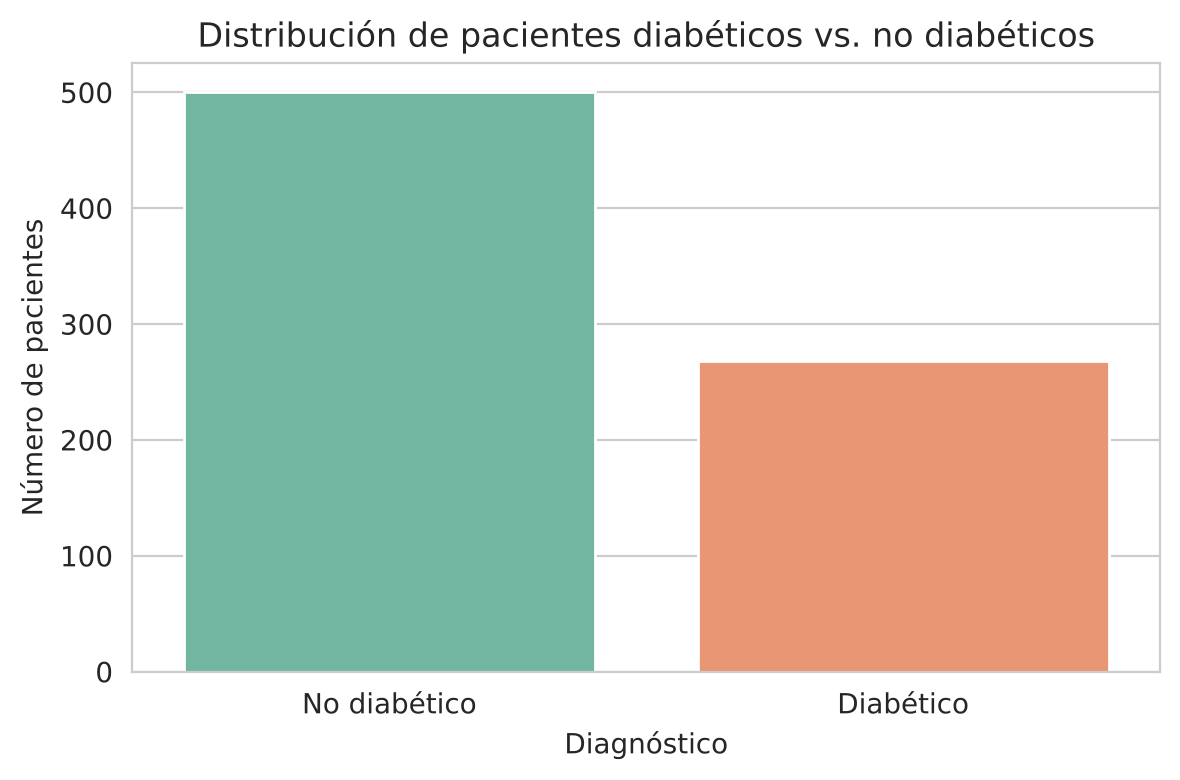

outcome_label
No diabético    65.1
Diabético       34.9
Name: proportion, dtype: float64


In [18]:
# Visualización 1: Distribución de la variable objetivo (balance de clases)
plt.figure(figsize=(6, 4))
ax = sns.countplot(x="outcome_label", data=df_clean, palette="Set2")
plt.title("Distribución de pacientes diabéticos vs. no diabéticos")
plt.xlabel("Diagnóstico")
plt.ylabel("Número de pacientes")
plt.tight_layout()
plt.savefig("viz1_balance_clases.png", dpi=100)
plt.show()

print(df_clean["outcome_label"].value_counts(normalize=True).round(3) * 100)

**Interpretación:** La clase "No diabético" representa aproximadamente el 65% de los registros y "Diabético" el 35% restante. Existe un **desbalance moderado de clases**, un aspecto importante a considerar en el siguiente periodo al momento de entrenar y evaluar los modelos de clasificación (podría requerirse balanceo con técnicas como SMOTE o ajuste de pesos).

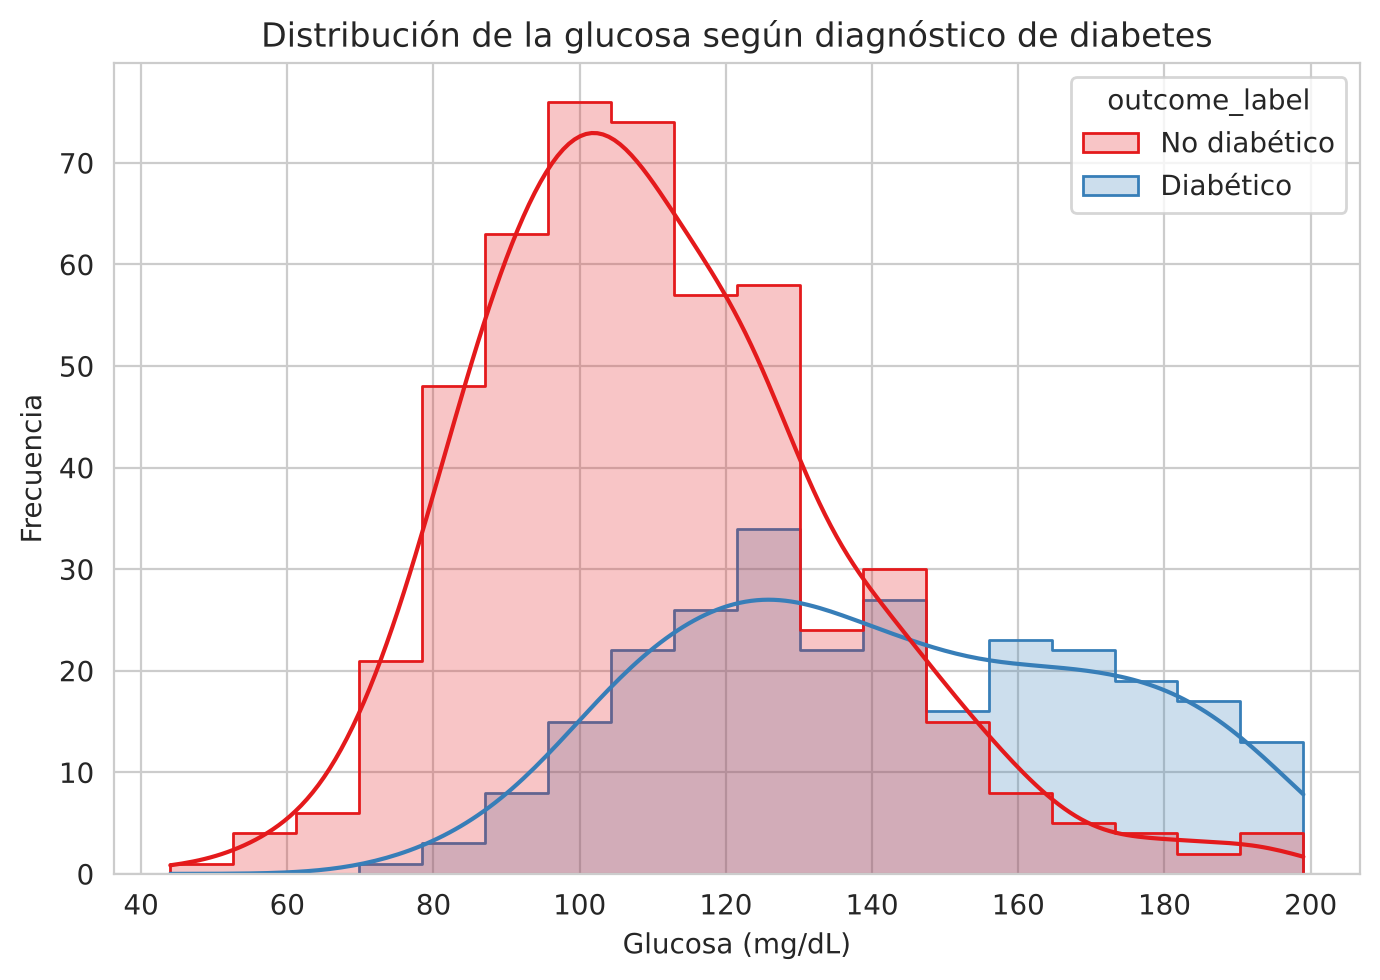

In [19]:
# Visualización 2: Distribución de Glucosa según diagnóstico
plt.figure(figsize=(7, 5))
sns.histplot(data=df_clean, x="glucose", hue="outcome_label", kde=True, element="step", palette="Set1")
plt.title("Distribución de la glucosa según diagnóstico de diabetes")
plt.xlabel("Glucosa (mg/dL)")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.savefig("viz2_glucosa.png", dpi=100)
plt.show()

**Interpretación:** Se observa que las pacientes diagnosticadas con diabetes tienden a concentrarse en niveles de glucosa más altos que las no diabéticas, lo cual es consistente con el criterio clínico de que la glucosa es uno de los indicadores más determinantes para el diagnóstico de la enfermedad. Esta variable probablemente tendrá alta importancia predictiva en los modelos de clasificación.

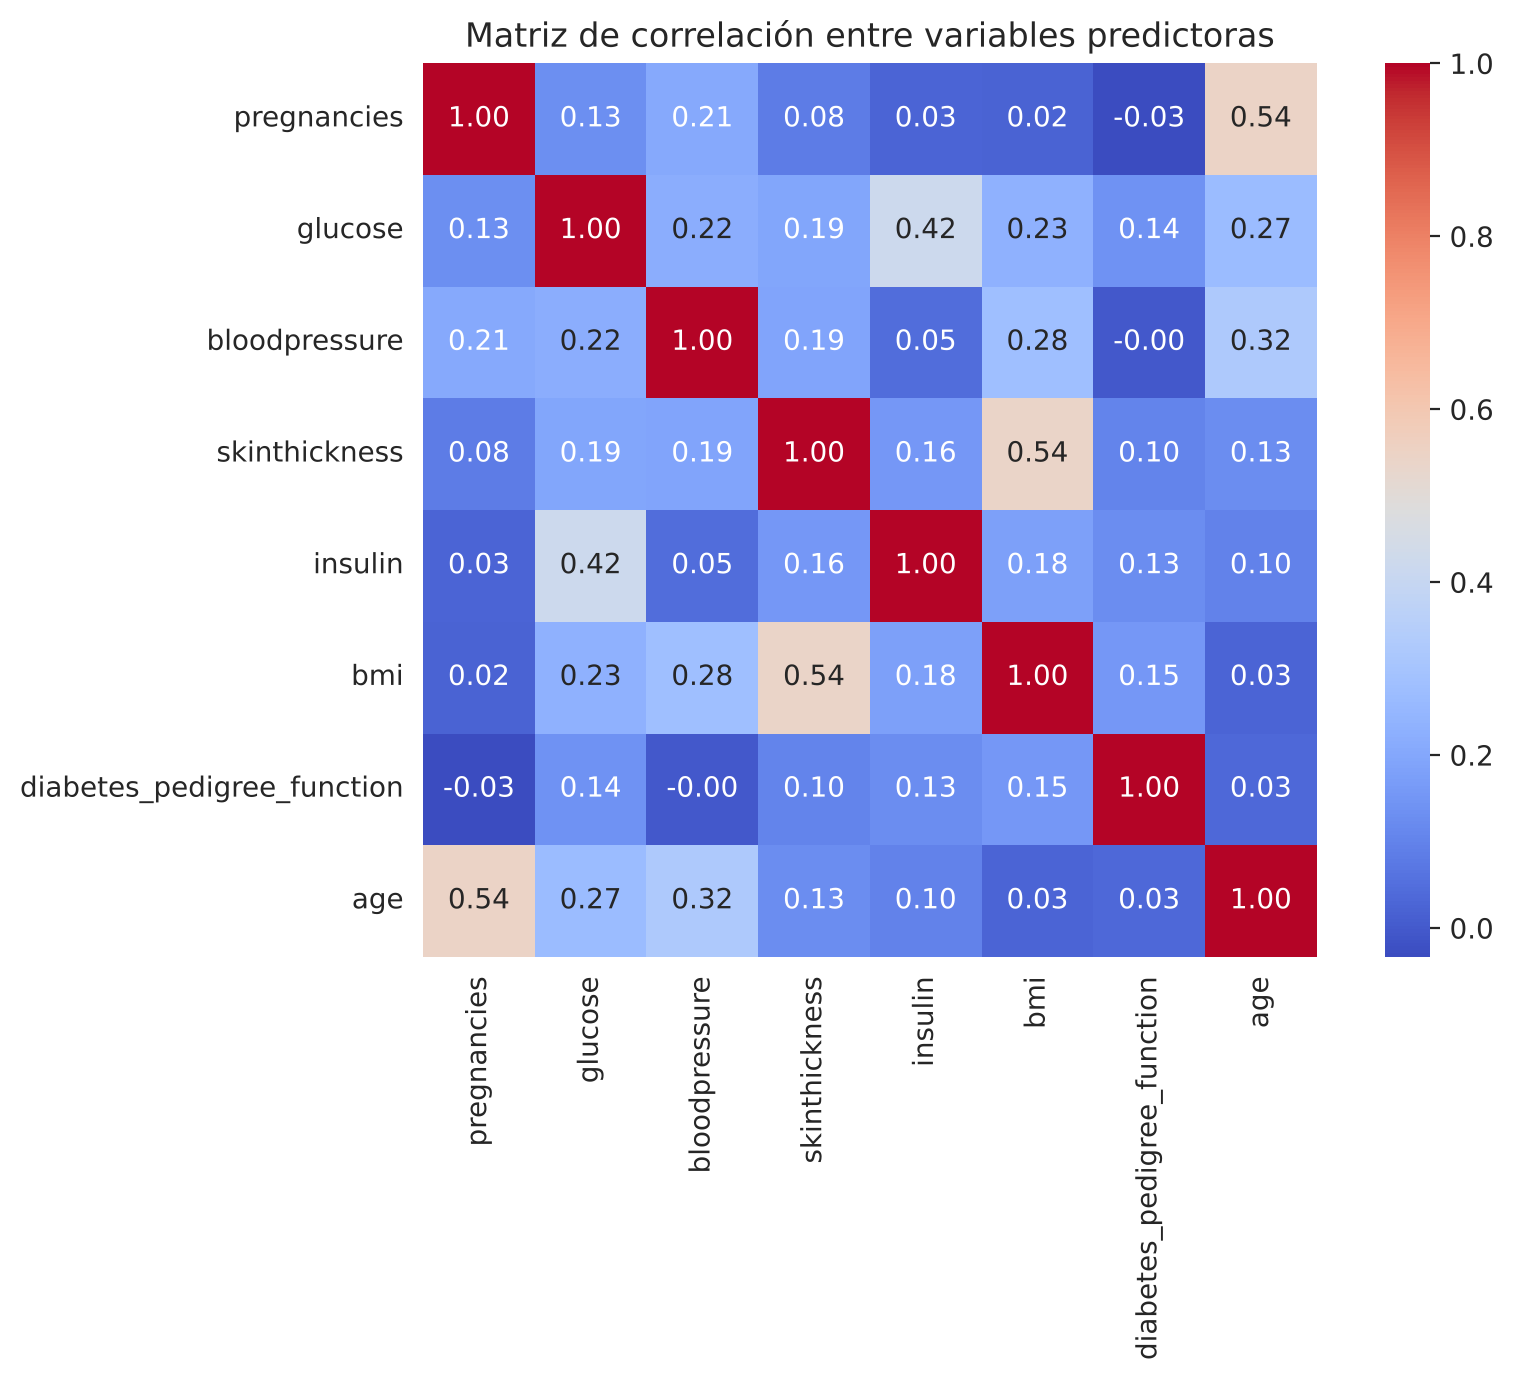

In [20]:
# Visualización 3: Matriz de correlación entre variables numéricas
plt.figure(figsize=(9, 7))
corr = df_clean[["pregnancies","glucose","bloodpressure","skinthickness",
                  "insulin","bmi","diabetes_pedigree_function","age"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", square=True)
plt.title("Matriz de correlación entre variables predictoras")
plt.tight_layout()
plt.savefig("viz3_correlacion.png", dpi=100)
plt.show()

**Interpretación:** La correlación más fuerte se observa entre `skinthickness` e `insulin`, y entre `age` y `pregnancies`, lo cual tiene sentido fisiológico y demográfico. Ninguna correlación es extremadamente alta (> 0.9), por lo que en principio no se anticipan problemas graves de multicolinealidad para el modelado posterior.

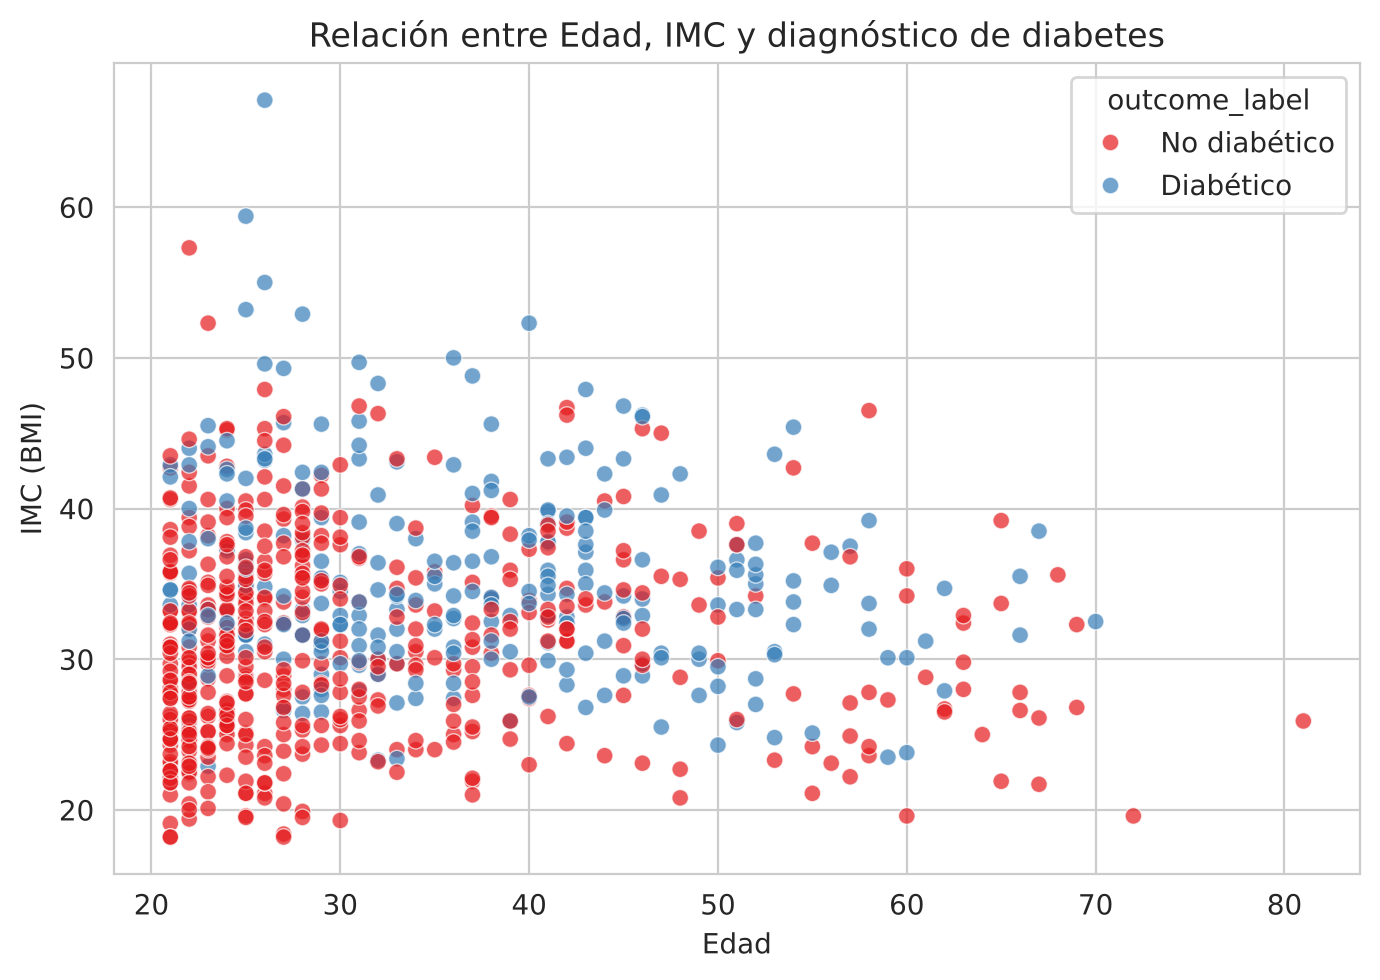

In [21]:
# Visualización 4 (extra): Relación entre edad, IMC y diagnóstico
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df_clean, x="age", y="bmi", hue="outcome_label", alpha=0.7, palette="Set1")
plt.title("Relación entre Edad, IMC y diagnóstico de diabetes")
plt.xlabel("Edad")
plt.ylabel("IMC (BMI)")
plt.tight_layout()
plt.savefig("viz4_edad_bmi.png", dpi=100)
plt.show()

**Interpretación:** Los casos diagnosticados con diabetes se distribuyen a lo largo de distintas edades, pero tienden a concentrarse en valores de IMC más altos, reforzando el vínculo clínico conocido entre sobrepeso/obesidad y riesgo de diabetes tipo 2.

## 7. Bitácora Breve de Uso de Inteligencia Artificial Generativa – Avance 1 (2.7)

- **Herramienta de IA utilizada:** Claude (Anthropic).
- **Prompt(s) utilizados:** "Ayúdame a estructurar un notebook de Python para la exploración inicial y limpieza de un dataset de diabetes (Pima Indians Diabetes), incluyendo diagnóstico de calidad de datos, limpieza y visualizaciones, siguiendo la rúbrica de un proyecto de aula sobre minería de datos en salud."
- **Propósito del uso de la IA:** Organizar la estructura general del notebook (secciones, orden lógico del análisis) y generar código base de exploración, limpieza y visualización en pandas/seaborn/matplotlib, para agilizar el desarrollo del primer avance del proyecto.
- **Qué respuesta fue útil:** La sugerencia de tratar los valores en 0 en variables clínicas como datos faltantes disfrazados (en lugar de asumirlos como válidos) y la propuesta de usar la mediana para la imputación, dado que es más robusta frente a outliers que la media.
- **Qué se tuvo que corregir, validar o ajustar:** El grupo revisó manualmente los umbrales de valores fisiológicamente imposibles (por ejemplo, que `Glucose`, `BloodPressure`, `BMI`, `SkinThickness` e `Insulin` no pueden ser 0 en una persona viva) antes de aceptar la limpieza sugerida, y decidió mantener `Pregnancies` sin modificar porque el valor 0 sí es válido en esa variable (una paciente puede no haber tenido embarazos).
- **Decisiones tomadas por el grupo (no por la IA):** La selección final del dataset y del tipo de proyecto (clasificación), la definición de la variable objetivo (`Outcome`), la decisión de imputar con la mediana en lugar de eliminar filas (para no perder información con un dataset de tamaño moderado, 768 registros), y la interpretación clínica de cada visualización fueron decisiones y validaciones realizadas por el grupo.

## 8. Conclusión Inicial – Avance 1 (2.8)

En esta primera revisión del dataset *Pima Indians Diabetes* se encontró que, si bien no existen valores nulos explícitos ni registros duplicados, el conjunto de datos presenta un problema de calidad relevante: varias variables clínicas (glucosa, presión arterial, espesor del pliegue cutáneo, insulina e IMC) contienen valores codificados como 0 que en realidad representan datos faltantes, ya que no son fisiológicamente posibles. Este hallazgo motivó el primer ajuste de limpieza, en el cual dichos ceros fueron reemplazados por la mediana de cada variable. También se identificó un desbalance moderado de clases en la variable objetivo (65% no diabéticos vs. 35% diabéticos) y la presencia de algunos outliers, especialmente en `Insulin` y `DiabetesPedigreeFunction`, que deberán tratarse con mayor profundidad más adelante. Las visualizaciones iniciales confirman relaciones clínicamente esperables, como la asociación entre niveles altos de glucosa e IMC con el diagnóstico positivo de diabetes. Para el segundo periodo académico se espera profundizar en el tratamiento de outliers, evaluar técnicas de balanceo de clases, realizar un análisis de importancia de variables y comenzar la construcción y comparación de los primeros modelos de clasificación (por ejemplo, regresión logística, árboles de decisión y random forest).

---
# SEGUNDO AVANCE

## 9. Preparación final de los datos para el modelado

A partir de la revisión del primer avance se confirma la versión final de los datos usada en el EDA y el entrenamiento:

- **Valores faltantes:** no hay `NaN` explícitos, pero `glucose`, `bloodpressure`, `skinthickness`, `insulin` y `bmi` tienen ceros fisiológicamente imposibles, que se convierten a `NaN`. `pregnancies` se deja igual porque 0 embarazos sí es válido.
- **Duplicados:** no hay registros duplicados (verificado en la sección 4).
- **Tipos de datos:** todas las predictoras son numéricas; no hay variables categóricas que codificar.
- **Identificadores y fuga de información:** el dataset no tiene columnas de identificación. Se excluye `outcome_label` porque es el objetivo en texto.
- **Outliers:** se conservan. Valores como insulina de 846 µU/ml o 17 embarazos son extremos pero posibles clínicamente; eliminarlos reduciría un dataset ya pequeño (768 registros). Los modelos basados en árboles son poco sensibles a outliers y para la regresión logística se aplica estandarización.
- **Imputación:** mediana, ajustada **solo** con el conjunto de entrenamiento (dentro del `Pipeline`).
- **Escalamiento:** `StandardScaler` para la regresión logística (sensible a la escala). Los árboles no lo necesitan.
- **Limitación conocida:** `insulin` tiene 48.7 % de valores faltantes y `skinthickness` 29.6 %; la imputación con la mediana reduce su variabilidad real, por lo que su aporte a los modelos debe interpretarse con cautela.

In [22]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay)

RANDOM_STATE = 42

# Versión final para el modelado: nombres estandarizados y ceros inválidos como NaN (SIN imputar todavía)
df_model = df.copy()
df_model.columns = [c.strip().lower() for c in df_model.columns]
df_model = df_model.rename(columns={"diabetespedigreefunction": "diabetes_pedigree_function"})
for col in cols_fix:
    df_model[col] = df_model[col].replace(0, np.nan)

print("Registros y variables del dataset final:", df_model.shape)
print("\nValores faltantes (que se imputarán dentro del Pipeline):")
print(df_model.isnull().sum())

Registros y variables del dataset final: (768, 9)

Valores faltantes (que se imputarán dentro del Pipeline):
pregnancies                     0
glucose                         5
bloodpressure                  35
skinthickness                 227
insulin                       374
bmi                            11
diabetes_pedigree_function      0
age                             0
outcome                         0
dtype: int64


## 10. Análisis Exploratorio de Datos ampliado

El EDA del primer avance mostró la distribución de la variable objetivo, la glucosa por diagnóstico, la matriz de correlación y la relación edad–IMC. En esta sección se complementa con comparaciones por clase de **todas** las predictoras, su correlación con el objetivo y tasas de diabetes por grupos de edad e IMC, con el fin de orientar las decisiones de modelado. Para el EDA se usa `df_clean` (versión imputada del avance 1); los resultados son asociaciones, no relaciones causales.

In [23]:
# Tabla 1. Mediana de cada variable según diagnóstico
predictoras = ["pregnancies","glucose","bloodpressure","skinthickness","insulin","bmi","diabetes_pedigree_function","age"]
tabla_medianas = df_model.groupby("outcome")[predictoras].median().T
tabla_medianas.columns = ["Mediana No diabético (0)", "Mediana Diabético (1)"]
tabla_medianas["Diferencia"] = tabla_medianas.iloc[:,1] - tabla_medianas.iloc[:,0]
print("Tabla 1. Mediana de las variables por clase (calculada sin incluir los valores faltantes)")
tabla_medianas.round(3)

Tabla 1. Mediana de las variables por clase (calculada sin incluir los valores faltantes)


,Mediana No diabético (0),Mediana Diabético (1),Diferencia
pregnancies,2.000,4.000,2.000
glucose,107.000,140.000,33.000
bloodpressure,70.000,74.500,4.500
skinthickness,27.000,32.000,5.000
insulin,102.500,169.500,67.000
bmi,30.100,34.300,4.200
diabetes_pedigree_function,0.336,0.449,0.113
age,27.000,36.000,9.000


**Interpretación (Tabla 1):** las pacientes diabéticas tienen medianas más altas en todas las variables. La diferencia más marcada es en `glucose` (140 vs. 107 mg/dL), seguida de `insulin` (169.5 vs. 102.5), `age` (36 vs. 27 años) y `bmi` (34.3 vs. 30.1). `bloodpressure` casi no cambia entre clases (74.5 vs. 70), lo que anticipa que aportará poco a la clasificación.

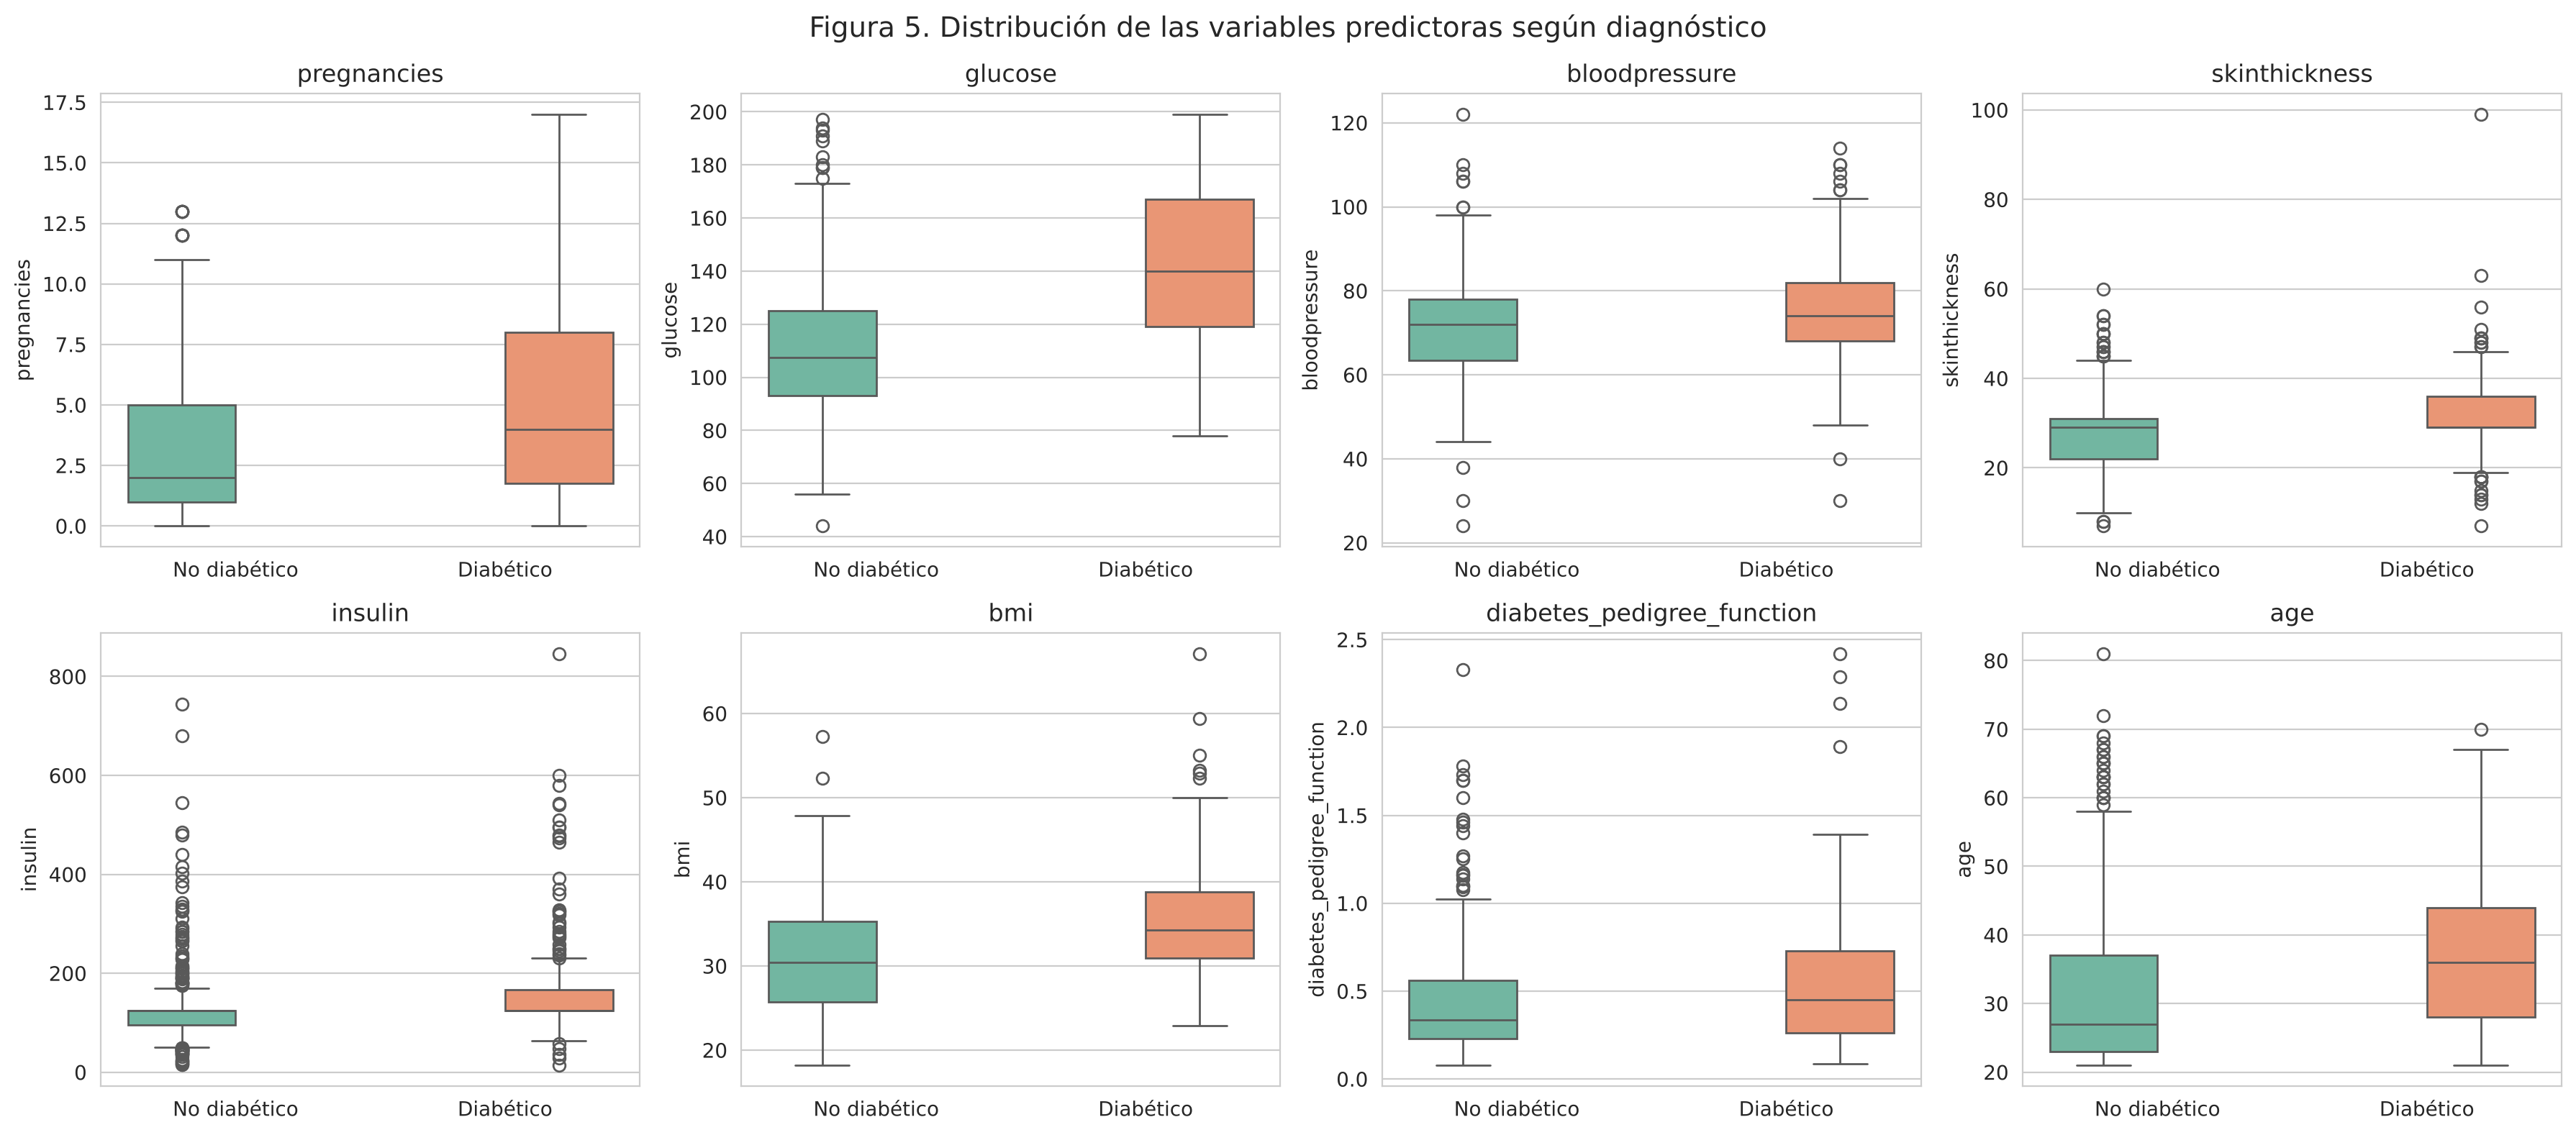

In [24]:
# Figura 5. Distribución de cada predictora por diagnóstico (boxplots)
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flatten(), predictoras):
    sns.boxplot(data=df_clean, x="outcome_label", y=col, hue="outcome_label", palette="Set2", legend=False, ax=ax)
    ax.set_title(col); ax.set_xlabel("")
fig.suptitle("Figura 5. Distribución de las variables predictoras según diagnóstico", fontsize=14)
plt.tight_layout()
plt.savefig("viz5_boxplots_por_clase.png", dpi=100)
plt.show()

**Interpretación (Figura 5):** las cajas de `glucose`, `bmi` y `age` están claramente desplazadas hacia arriba en el grupo diabético, con poco solapamiento en el caso de la glucosa. En `insulin` y `skinthickness` muchos puntos se concentran en la mediana, efecto de la imputación de los ceros. `bloodpressure` presenta cajas muy similares en ambos grupos. Los outliers aparecen en las dos clases, por lo que no son exclusivos de un diagnóstico.

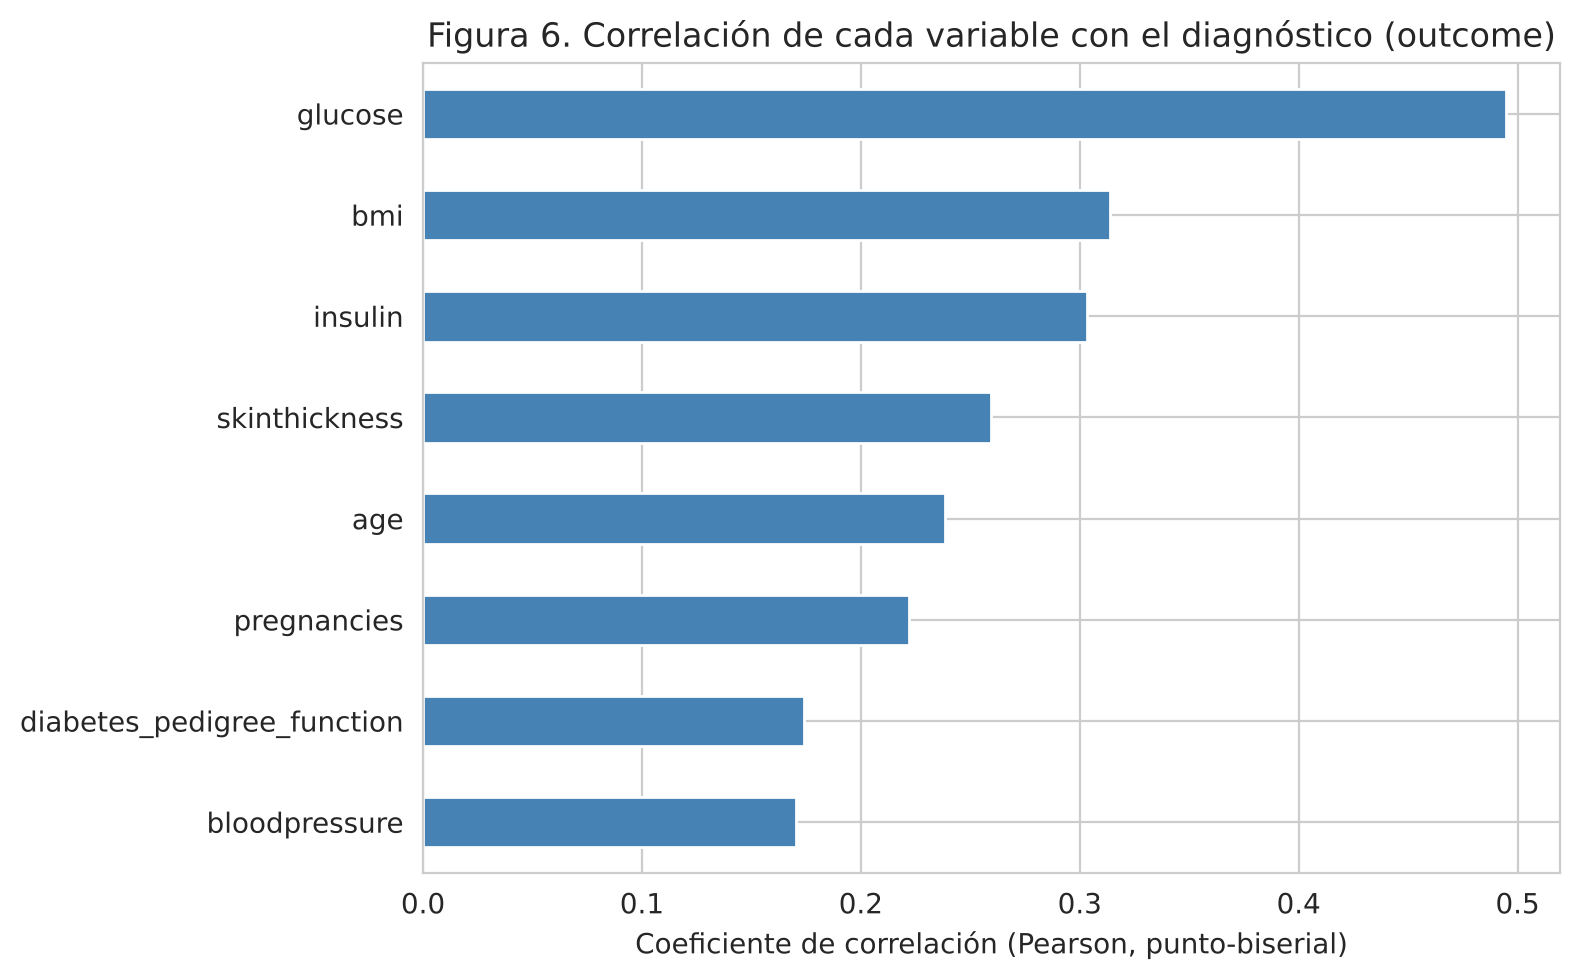

bloodpressure                 0.171
diabetes_pedigree_function    0.174
pregnancies                   0.222
age                           0.238
skinthickness                 0.259
insulin                       0.303
bmi                           0.314
glucose                       0.495
dtype: float64


In [25]:
# Figura 6. Correlación de cada predictora con la variable objetivo
corr_obj = df_model[predictoras].corrwith(df_model["outcome"]).sort_values()
plt.figure(figsize=(8, 5))
corr_obj.plot(kind="barh", color="steelblue")
plt.title("Figura 6. Correlación de cada variable con el diagnóstico (outcome)")
plt.xlabel("Coeficiente de correlación (Pearson, punto‑biserial)")
plt.tight_layout()
plt.savefig("viz6_correlacion_objetivo.png", dpi=100)
plt.show()
print(corr_obj.round(3))

**Interpretación (Figura 6):** `glucose` es la variable con mayor asociación lineal con el diagnóstico (r ≈ 0.49), seguida de `bmi` (≈ 0.31) e `insulin` (≈ 0.30). `bloodpressure` (≈ 0.17) y `diabetes_pedigree_function` (≈ 0.17) son las de menor asociación. Ninguna correlación es suficientemente alta como para que una sola variable resuelva el problema, lo que justifica usar modelos multivariados.

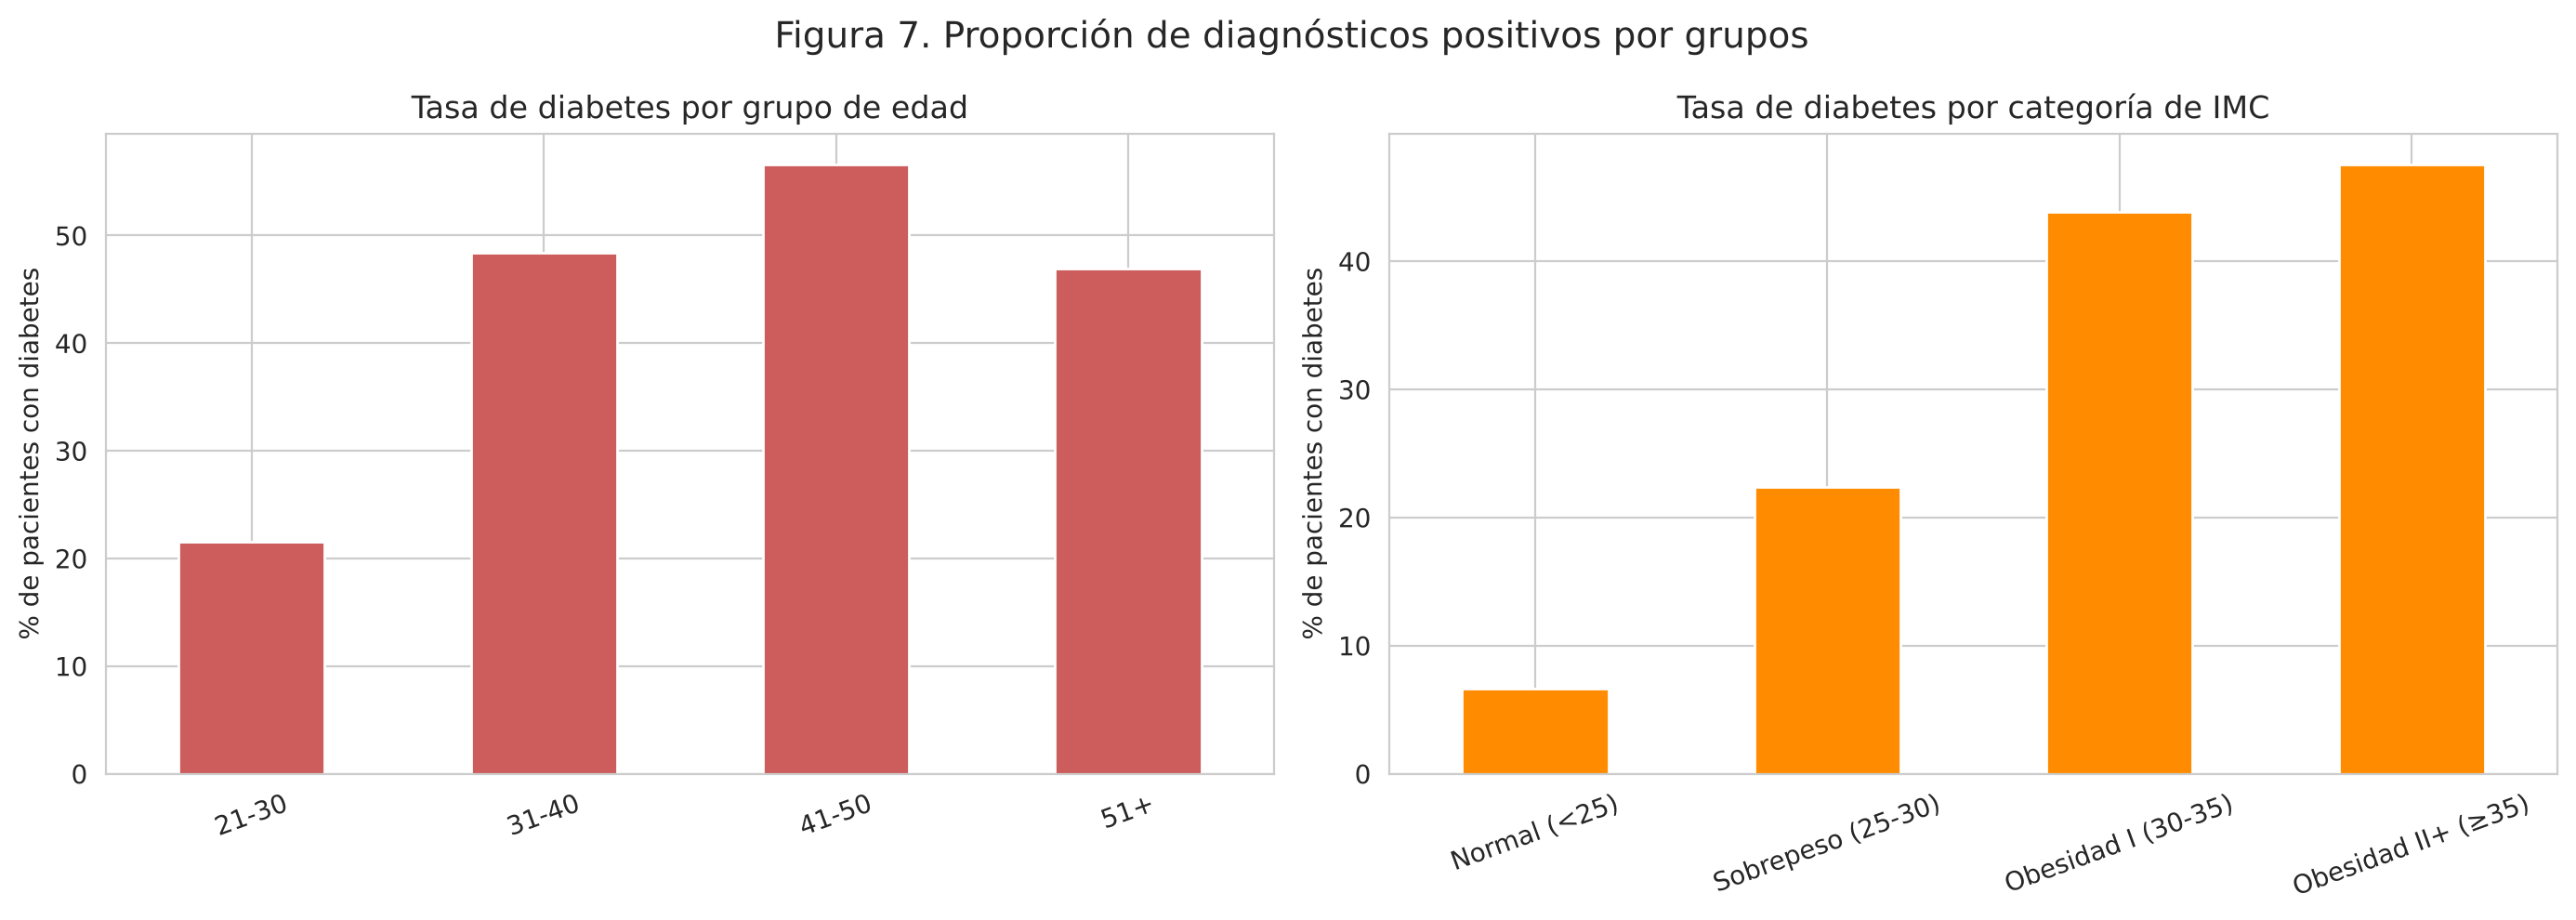

Tasa de diabetes (%) por grupo de edad:
grupo_edad
21-30    21.6
31-40    48.4
41-50    56.6
51+      46.9
Name: outcome_num, dtype: float64

Tasa de diabetes (%) por categoría de IMC:
categoria_imc
Normal (<25)           6.6
Sobrepeso (25-30)     22.3
Obesidad I (30-35)    43.8
Obesidad II+ (≥35)    47.6
Name: outcome_num, dtype: float64

Número de pacientes por grupo de edad:
grupo_edad
21-30    417
31-40    157
41-50    113
51+       81
Name: count, dtype: int64


In [26]:
# Figura 7. Tasa de diabetes por grupo de edad y por categoría de IMC
df_eda = df_clean.copy()
df_eda["outcome_num"] = df_eda["outcome"].astype(int)
df_eda["grupo_edad"] = pd.cut(df_eda["age"], bins=[20, 30, 40, 50, 90], labels=["21-30", "31-40", "41-50", "51+"])
df_eda["categoria_imc"] = pd.cut(df_eda["bmi"], bins=[0, 25, 30, 35, 100],
                                 labels=["Normal (<25)", "Sobrepeso (25-30)", "Obesidad I (30-35)", "Obesidad II+ (≥35)"], right=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
tasa_edad = df_eda.groupby("grupo_edad", observed=True)["outcome_num"].mean() * 100
tasa_imc = df_eda.groupby("categoria_imc", observed=True)["outcome_num"].mean() * 100
tasa_edad.plot(kind="bar", ax=axes[0], color="indianred"); axes[0].set_title("Tasa de diabetes por grupo de edad")
tasa_imc.plot(kind="bar", ax=axes[1], color="darkorange"); axes[1].set_title("Tasa de diabetes por categoría de IMC")
for ax in axes:
    ax.set_ylabel("% de pacientes con diabetes"); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=20)
fig.suptitle("Figura 7. Proporción de diagnósticos positivos por grupos", fontsize=14)
plt.tight_layout()
plt.savefig("viz7_tasas_grupos.png", dpi=100)
plt.show()

print("Tasa de diabetes (%) por grupo de edad:"); print(tasa_edad.round(1))
print("\nTasa de diabetes (%) por categoría de IMC:"); print(tasa_imc.round(1))
print("\nNúmero de pacientes por grupo de edad:"); print(df_eda["grupo_edad"].value_counts().sort_index())

**Interpretación (Figura 7):** la proporción de diagnósticos positivos pasa de 21.6 % en el grupo de 21–30 años a 56.6 % en el de 41–50 años, y baja a 46.9 % en el de 51+ (grupo con solo 81 registros, por lo que su tasa es menos estable). Por IMC, la tasa es de apenas 6.6 % con IMC normal y crece de forma sostenida hasta 47.6 % con obesidad grado II o más. Esto coincide con lo observado en la última visualización del primer avance (edad vs. IMC).

**Decisiones de modelado derivadas del EDA:**
1. Se usarán **todas** las predictoras: aunque `bloodpressure` aporta poco, no hay razones para excluirla y los modelos pueden asignarle bajo peso.
2. El **desbalance** (65 % / 35 %) obliga a usar división **estratificada** y a no evaluar solo con accuracy: un modelo que predijera siempre "No diabético" tendría 65 % de accuracy sin detectar a ninguna paciente.
3. Como las variables tienen escalas muy distintas (`insulin` hasta 846, `diabetes_pedigree_function` hasta 2.4), se escalan los datos para la regresión logística.

## 11. Selección y entrenamiento de modelos

**Modelos seleccionados y justificación:**
- **Regresión logística:** modelo base, interpretable (coeficientes) y usado en los antecedentes revisados (Dubey et al., 2021). Requiere escalamiento.
- **Regresión logística con `class_weight="balanced"`:** misma técnica, pero da más peso a la clase minoritaria (diabéticas). Se incluye porque en un problema de tamizaje es más grave no detectar a una paciente diabética (falso negativo) que generar una falsa alarma. No es una optimización de hiperparámetros, sino una forma de tratar el desbalance identificado en el EDA.
- **Árbol de decisión:** modelo no lineal e interpretable, visto en clase.
- **Random Forest:** conjunto de árboles que reduce el sobreajuste de un árbol individual; también usado en los antecedentes.

Todos los modelos usan los **hiperparámetros por defecto** de scikit-learn (no se exige búsqueda de hiperparámetros en esta entrega) y `random_state=42` para reproducibilidad.

**Separación de datos:** 80 % entrenamiento / 20 % prueba, estratificada por `outcome` para conservar la proporción de clases.

In [27]:
# Separación entre predictoras (X) y variable objetivo (y)
X = df_model[predictoras]
y = df_model["outcome"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print(f"Entrenamiento: {X_train.shape[0]} registros | Prueba: {X_test.shape[0]} registros")
print(f"Proporción de diabéticas -> entrenamiento: {y_train.mean():.3f} | prueba: {y_test.mean():.3f}")

Entrenamiento: 614 registros | Prueba: 154 registros
Proporción de diabéticas -> entrenamiento: 0.349 | prueba: 0.351


In [28]:
# Pipelines: la imputación (y el escalamiento cuando aplica) se ajustan SOLO con X_train
imputador = ("imputador", SimpleImputer(strategy="median"))
modelos = {
    "Regresión logística": Pipeline([imputador, ("escalador", StandardScaler()),
                                     ("modelo", LogisticRegression(max_iter=1000))]),
    "Regresión logística (balanceada)": Pipeline([imputador, ("escalador", StandardScaler()),
                                                  ("modelo", LogisticRegression(max_iter=1000, class_weight="balanced"))]),
    "Árbol de decisión": Pipeline([imputador, ("modelo", DecisionTreeClassifier(random_state=RANDOM_STATE))]),
    "Random Forest": Pipeline([imputador, ("modelo", RandomForestClassifier(random_state=RANDOM_STATE))]),
}

predicciones, probabilidades = {}, {}
for nombre, pipe in modelos.items():
    pipe.fit(X_train, y_train)
    predicciones[nombre] = pipe.predict(X_test)
    probabilidades[nombre] = pipe.predict_proba(X_test)[:, 1]
    print(f"Modelo entrenado: {nombre}")

Modelo entrenado: Regresión logística
Modelo entrenado: Regresión logística (balanceada)
Modelo entrenado: Árbol de decisión


Modelo entrenado: Random Forest


## 12. Evaluación e interpretación

### 12.1 Métricas sobre el conjunto de prueba
Se reportan accuracy, precision, recall, F1-score y AUC-ROC. Precision, recall y F1 se calculan para la **clase positiva (diabetes = 1)**, que es la de mayor interés clínico.

In [29]:
filas = []
for nombre, pipe in modelos.items():
    p, pr = predicciones[nombre], probabilidades[nombre]
    filas.append({
        "Modelo": nombre,
        "Accuracy entrenamiento": accuracy_score(y_train, pipe.predict(X_train)),
        "Accuracy prueba": accuracy_score(y_test, p),
        "Precision (1)": precision_score(y_test, p),
        "Recall (1)": recall_score(y_test, p),
        "F1-score (1)": f1_score(y_test, p),
        "AUC-ROC": roc_auc_score(y_test, pr),
    })
tabla_metricas = pd.DataFrame(filas).set_index("Modelo").round(3)
print("Tabla 2. Métricas de los modelos en el conjunto de prueba (154 registros)")
tabla_metricas

Tabla 2. Métricas de los modelos en el conjunto de prueba (154 registros)


,Accuracy entrenamiento,Accuracy prueba,Precision (1),Recall (1),F1-score (1),AUC-ROC
Modelo,,,,,,
Regresión logística,0.796,0.708,0.600,0.500,0.545,0.813
Regresión logística (balanceada),0.759,0.734,0.603,0.704,0.650,0.813
Árbol de decisión,1.000,0.682,0.553,0.481,0.515,0.636
Random Forest,1.000,0.766,0.696,0.593,0.640,0.821


In [30]:
# Resultados por clase de cada modelo
for nombre in modelos:
    print("=" * 70)
    print(nombre)
    print(classification_report(y_test, predicciones[nombre], target_names=["No diabético", "Diabético"], digits=3))

Regresión logística
              precision    recall  f1-score   support

No diabético      0.752     0.820     0.785       100
   Diabético      0.600     0.500     0.545        54

    accuracy                          0.708       154
   macro avg      0.676     0.660     0.665       154
weighted avg      0.699     0.708     0.701       154

Regresión logística (balanceada)
              precision    recall  f1-score   support

No diabético      0.824     0.750     0.785       100
   Diabético      0.603     0.704     0.650        54

    accuracy                          0.734       154
   macro avg      0.714     0.727     0.717       154
weighted avg      0.747     0.734     0.738       154

Árbol de decisión
              precision    recall  f1-score   support

No diabético      0.738     0.790     0.763       100
   Diabético      0.553     0.481     0.515        54

    accuracy                          0.682       154
   macro avg      0.646     0.636     0.639       154
wei

**Interpretación (Tabla 2 y reportes por clase):**
- **Random Forest** obtiene la mayor accuracy (0.766) y la mayor precision (0.696), pero su recall es 0.593: no detecta cerca de 4 de cada 10 pacientes diabéticas.
- **Regresión logística (balanceada)** tiene el **mayor recall (0.704)** y el **mayor F1 (0.650)**, con accuracy de 0.734. Detecta más pacientes diabéticas a costa de algunas falsas alarmas más.
- **Regresión logística** sin balanceo tiene recall de solo 0.500: el modelo se inclina hacia la clase mayoritaria.
- **Árbol de decisión** es el de peor desempeño (accuracy 0.682, AUC 0.636) y muestra **sobreajuste**: accuracy de 1.000 en entrenamiento frente a 0.682 en prueba, porque sin límite de profundidad memoriza los datos. Random Forest también llega a 1.000 en entrenamiento, pero al promediar muchos árboles generaliza mejor.
- Para la clase "No diabético" todos los modelos tienen recall alto (≥ 0.75), lo que confirma que el problema principal está en detectar la clase minoritaria.

### 12.2 Matrices de confusión

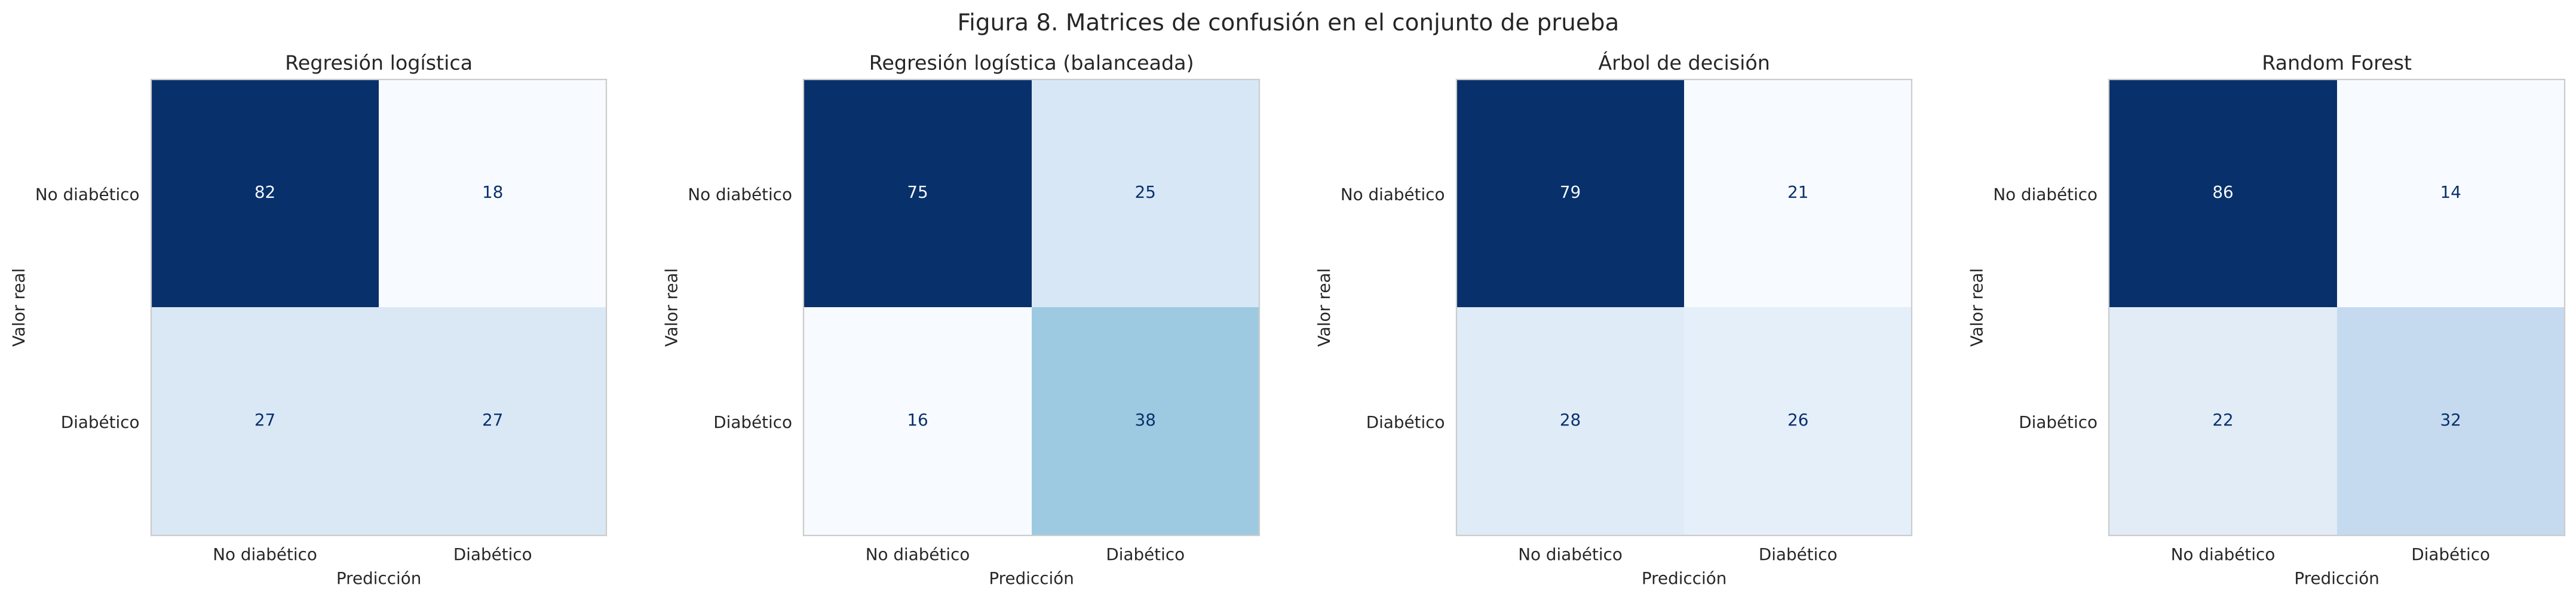

Tabla 3. Desglose de aciertos y errores (54 diabéticas y 100 no diabéticas en prueba)


,VN,FP (falsa alarma),FN (diabética no detectada),VP
Modelo,,,,
Regresión logística,82,18,27,27
Regresión logística (balanceada),75,25,16,38
Árbol de decisión,79,21,28,26
Random Forest,86,14,22,32


In [31]:
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
for ax, nombre in zip(axes, modelos):
    ConfusionMatrixDisplay.from_predictions(
        y_test, predicciones[nombre], display_labels=["No diabético", "Diabético"],
        cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(nombre); ax.grid(False)
    ax.set_xlabel("Predicción"); ax.set_ylabel("Valor real")
fig.suptitle("Figura 8. Matrices de confusión en el conjunto de prueba", fontsize=14)
plt.tight_layout()
plt.savefig("viz8_matrices_confusion.png", dpi=100)
plt.show()

errores = []
for nombre in modelos:
    tn, fp, fn, tp = confusion_matrix(y_test, predicciones[nombre]).ravel()
    errores.append({"Modelo": nombre, "VN": tn, "FP (falsa alarma)": fp, "FN (diabética no detectada)": fn, "VP": tp})
print("Tabla 3. Desglose de aciertos y errores (54 diabéticas y 100 no diabéticas en prueba)")
pd.DataFrame(errores).set_index("Modelo")

**Interpretación (Figura 8 y Tabla 3):** el error más relevante en este problema es el **falso negativo** (paciente diabética clasificada como sana), porque implica no remitirla a exámenes confirmatorios. De las 54 pacientes diabéticas del conjunto de prueba:
- la regresión logística balanceada deja sin detectar **16**, a cambio de **25** falsas alarmas;
- Random Forest deja sin detectar **22**, con solo **14** falsas alarmas;
- la regresión logística sin balanceo deja sin detectar **27** (la mitad);
- el árbol de decisión deja sin detectar **28**.

Un falso positivo en este contexto solo conduce a una prueba adicional de glucosa, que es de bajo costo, mientras que un falso negativo retrasa el diagnóstico. Por eso la regresión logística balanceada es la opción más adecuada para un uso de tamizaje, aunque Random Forest tenga mayor accuracy.

### 12.3 Validación cruzada (5 particiones estratificadas sobre el entrenamiento)
El conjunto de prueba tiene solo 154 registros, por lo que una sola partición puede dar resultados inestables. La validación cruzada estima el desempeño promedio y su variabilidad sin usar los datos de prueba.

In [32]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
filas_cv = []
for nombre, pipe in modelos.items():
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["accuracy", "precision", "recall", "f1", "roc_auc"])
    fila = {"Modelo": nombre}
    for m in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
        fila[m] = f"{r['test_' + m].mean():.3f} ± {r['test_' + m].std():.3f}"
    filas_cv.append(fila)
print("Tabla 4. Validación cruzada de 5 particiones (media ± desviación estándar)")
pd.DataFrame(filas_cv).set_index("Modelo")

Tabla 4. Validación cruzada de 5 particiones (media ± desviación estándar)


,accuracy,precision,recall,f1,roc_auc
Modelo,,,,,
Regresión logística,0.788 ± 0.019,0.764 ± 0.060,0.575 ± 0.023,0.655 ± 0.024,0.843 ± 0.019
Regresión logística (balanceada),0.762 ± 0.011,0.649 ± 0.026,0.701 ± 0.039,0.672 ± 0.013,0.844 ± 0.016
Árbol de decisión,0.673 ± 0.023,0.531 ± 0.037,0.580 ± 0.050,0.552 ± 0.027,0.651 ± 0.021
Random Forest,0.761 ± 0.019,0.690 ± 0.042,0.575 ± 0.038,0.626 ± 0.027,0.816 ± 0.022


**Interpretación (Tabla 4):** la validación cruzada confirma el orden observado en prueba: la regresión logística balanceada mantiene el mayor recall (≈ 0.70) y el mayor F1 (≈ 0.67), con AUC ≈ 0.84 igual a la regresión logística sin balancear. El árbol de decisión vuelve a ser el más débil (AUC ≈ 0.65). La regresión logística sin balanceo obtuvo 0.788 de accuracy en validación cruzada pero 0.708 en prueba: esa diferencia muestra la variabilidad de evaluar con una sola partición pequeña y refuerza la necesidad de considerar varias evidencias.

### 12.4 Curvas ROC

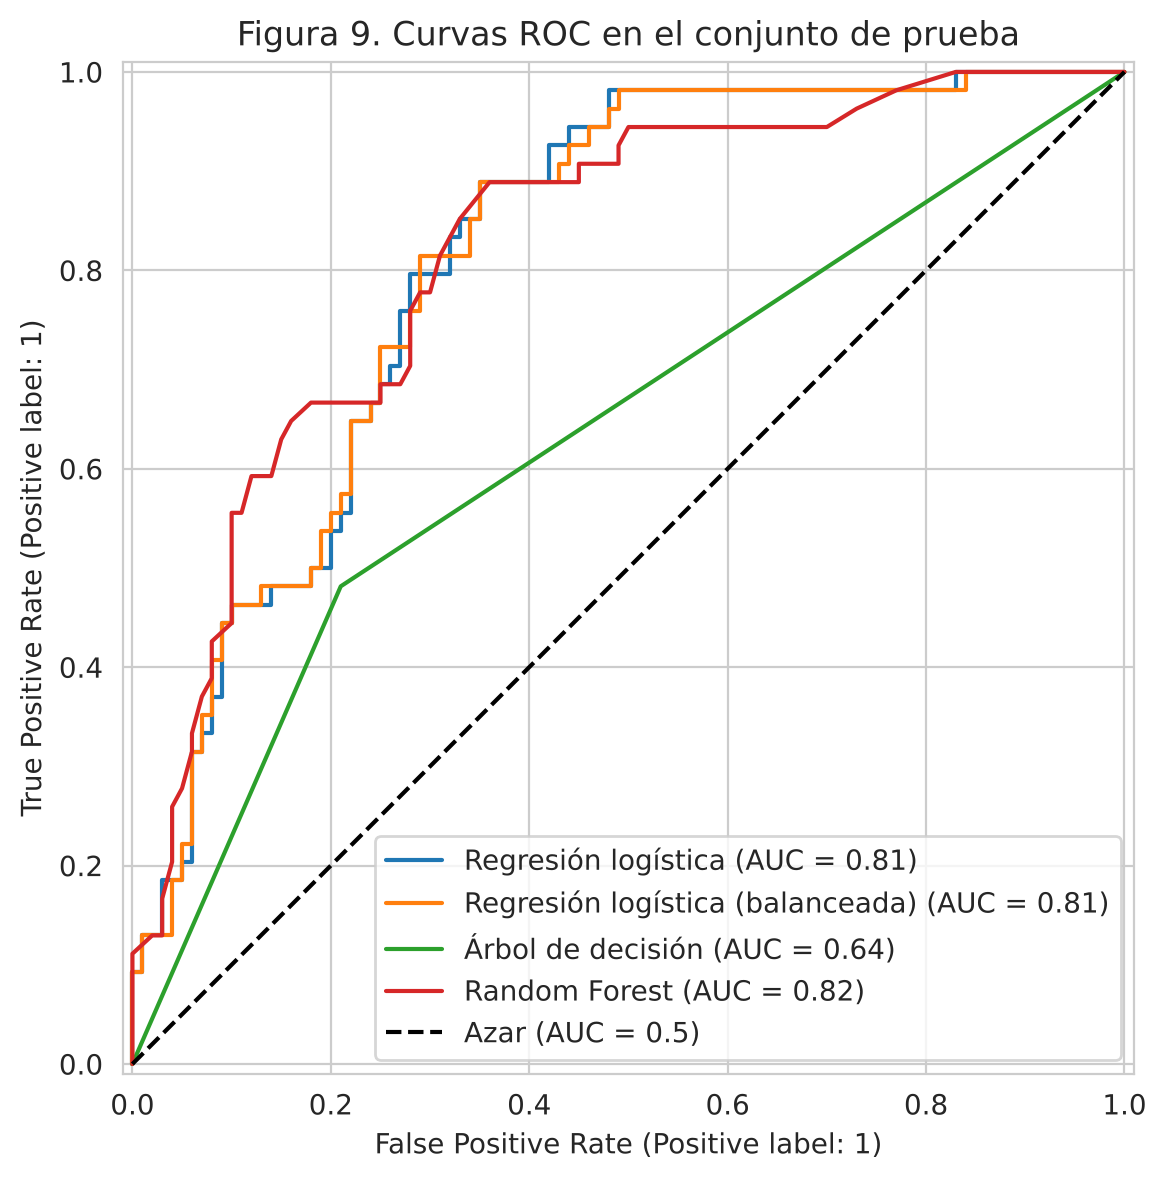

In [33]:
fig, ax = plt.subplots(figsize=(7, 6))
for nombre in modelos:
    RocCurveDisplay.from_predictions(y_test, probabilidades[nombre], name=nombre, ax=ax)
ax.plot([0, 1], [0, 1], "k--", label="Azar (AUC = 0.5)")
ax.set_title("Figura 9. Curvas ROC en el conjunto de prueba")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("viz9_curvas_roc.png", dpi=100)
plt.show()

**Interpretación (Figura 9):** las dos regresiones logísticas comparten la misma curva ROC (AUC 0.813), porque el balanceo de clases desplaza el punto de corte pero casi no cambia el orden de las probabilidades. Random Forest tiene un AUC similar (0.821). El árbol de decisión queda muy por debajo, cerca de la diagonal en varios tramos.

### 12.5 Variables más influyentes

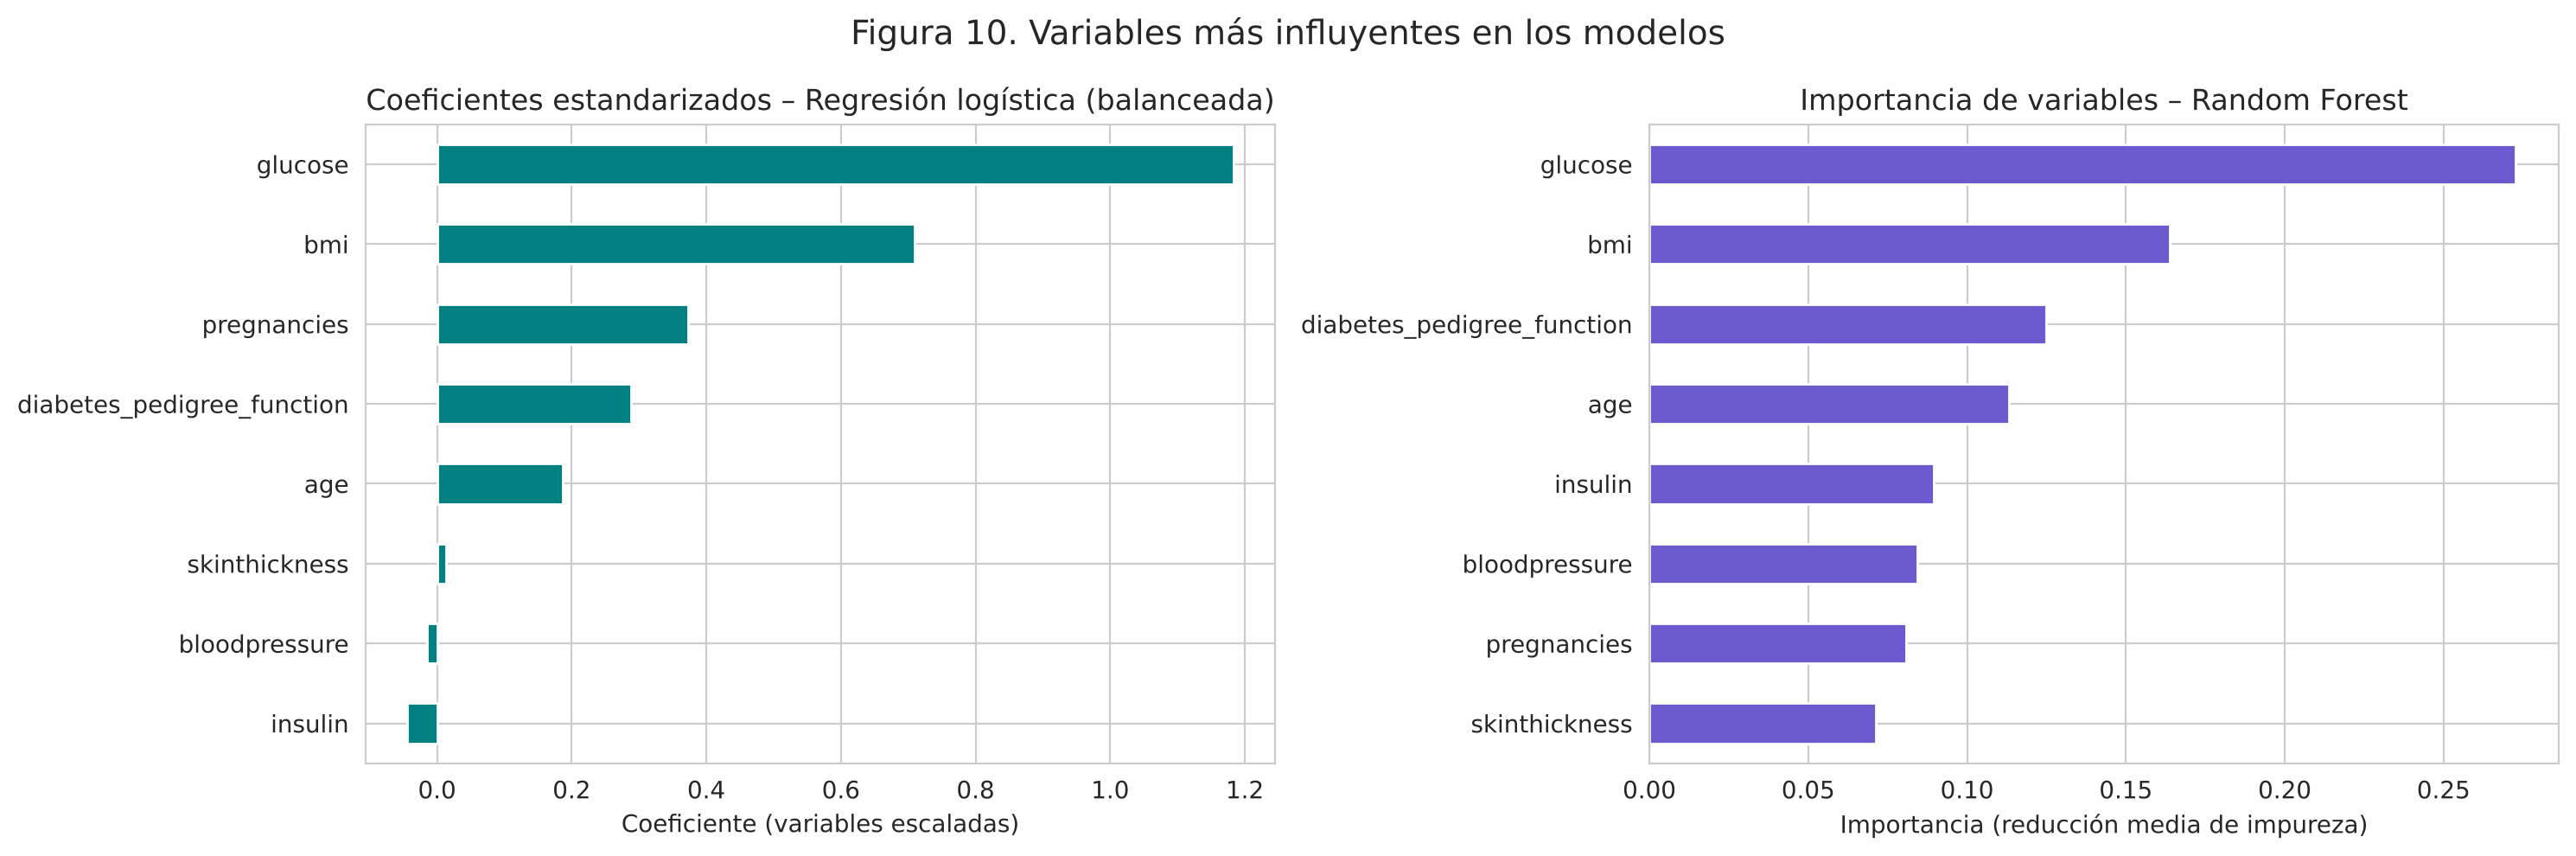

Coeficientes LR balanceada:
insulin                      -0.045
bloodpressure                -0.015
skinthickness                 0.014
age                           0.186
diabetes_pedigree_function    0.288
pregnancies                   0.373
bmi                           0.710
glucose                       1.183
dtype: float64

Importancias Random Forest:
skinthickness                 0.071
pregnancies                   0.081
bloodpressure                 0.084
insulin                       0.089
age                           0.113
diabetes_pedigree_function    0.125
bmi                           0.164
glucose                       0.273
dtype: float64


In [34]:
coef = modelos["Regresión logística (balanceada)"].named_steps["modelo"].coef_[0]
importancias_lr = pd.Series(coef, index=predictoras).sort_values()
importancias_rf = pd.Series(modelos["Random Forest"].named_steps["modelo"].feature_importances_,
                            index=predictoras).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
importancias_lr.plot(kind="barh", ax=axes[0], color="teal")
axes[0].set_title("Coeficientes estandarizados – Regresión logística (balanceada)")
axes[0].set_xlabel("Coeficiente (variables escaladas)")
importancias_rf.plot(kind="barh", ax=axes[1], color="slateblue")
axes[1].set_title("Importancia de variables – Random Forest")
axes[1].set_xlabel("Importancia (reducción media de impureza)")
fig.suptitle("Figura 10. Variables más influyentes en los modelos", fontsize=14)
plt.tight_layout()
plt.savefig("viz10_importancia_variables.png", dpi=100)
plt.show()
print("Coeficientes LR balanceada:"); print(importancias_lr.round(3))
print("\nImportancias Random Forest:"); print(importancias_rf.round(3))

**Interpretación (Figura 10):** ambos modelos coinciden en que `glucose` es la variable más influyente, seguida de `bmi`, lo que es coherente con el EDA (Figura 6) y con el conocimiento clínico. En la regresión logística, `bloodpressure` e `insulin` tienen coeficientes cercanos a cero; en el caso de la insulina esto puede deberse en parte a que casi la mitad de sus valores fueron imputados. Estas importancias indican **asociación** dentro del modelo, no causalidad.

## 13. Conclusiones del segundo avance

**¿Cuáles fueron los principales hallazgos del EDA?**
La glucosa es la variable con mayor diferencia entre clases (mediana 140 vs. 107 mg/dL) y la de mayor correlación con el diagnóstico (r ≈ 0.49), seguida del IMC, la insulina y la edad. La tasa de diabetes aumenta con el IMC y con la edad. La presión arterial casi no difiere entre clases. Existe un desbalance moderado (65 % / 35 %) y dos variables (`insulin` y `skinthickness`) tienen una proporción alta de datos faltantes.

**¿Qué modelo produjo los resultados más adecuados?**
La **regresión logística con pesos balanceados**.

**¿Qué evidencias respaldan esa selección?**
Tiene el mayor recall para la clase diabética en prueba (0.704) y en validación cruzada (≈ 0.70), el mayor F1 (0.650 en prueba, ≈ 0.67 en validación cruzada) y un AUC de 0.813 (≈ 0.84 en validación cruzada), comparable con Random Forest. Deja sin detectar 16 de 54 pacientes diabéticas, frente a 22 de Random Forest. Además, es interpretable y no presenta el sobreajuste de los modelos de árboles. Random Forest sería preferible solo si el objetivo fuera minimizar las falsas alarmas (precision 0.696).

**¿Qué errores o limitaciones se identificaron?**
- Aún se pierden 16 de 54 pacientes diabéticas (≈ 30 %) y se generan 25 falsas alarmas.
- El árbol de decisión sin restricciones sobreajusta (accuracy 1.000 en entrenamiento y 0.682 en prueba).
- El conjunto de prueba es pequeño (154 registros), por lo que las métricas varían según la partición.
- La imputación de casi la mitad de los valores de insulina limita la información real de esa variable.
- El dataset solo incluye mujeres de ascendencia Pima de 21 años o más, por lo que los resultados no se pueden generalizar a otras poblaciones.

**Pendiente para el tercer corte:** ajuste de hiperparámetros (por ejemplo, profundidad del árbol y umbral de decisión de la regresión logística), evaluación de técnicas de balanceo como SMOTE, comparación con otros imputadores y desarrollo del dashboard.

## 14. Declaración y evaluación del uso de inteligencia artificial – Avance 2

| Elemento | Información |
|---|---|
| **Herramienta utilizada** | Claude (Anthropic). |
| **Propósito** | Proponer la estructura del notebook del segundo avance, el código de los pipelines, métricas, matrices de confusión, validación cruzada y gráficas, y una primera redacción de las interpretaciones. |
| **Prompt** | *"Con base en el notebook del primer avance (Proyecto_Diabetes.ipynb), el informe del primer corte y el enunciado del Avance 2 adjuntos, continúa el notebook con la preparación final de datos, un EDA ampliado orientado a la pregunta, el entrenamiento y comparación de al menos dos modelos de clasificación, sus métricas (accuracy, precision, recall, F1, resultados por clase) y matrices de confusión, y las conclusiones; y continúa el informe con metodología, resultados preliminares y la declaración de uso de IA."* |
| **Problemas identificados** | (1) La limpieza del primer avance imputaba con la mediana de todo el dataset, lo que genera fuga de información si se usa para entrenar; se detectó al revisar la propuesta. (2) Una versión inicial de las interpretaciones podía escribirse antes de ejecutar el código, con riesgo de cifras que no coincidieran con las salidas. (3) Se propuso incluir una variante balanceada de la regresión logística, que no estaba en la lista mínima del enunciado. (4) Algunas referencias de profesores CUC sugeridas debían verificarse porque no todas las búsquedas pudieron consultarse. |
| **Ajustes realizados** | Se movió la imputación al `Pipeline` para ajustarla solo con el entrenamiento; todas las cifras de las interpretaciones se comprobaron contra las salidas ejecutadas; se mantuvieron los hiperparámetros por defecto (el enunciado no pide optimización); se conservaron solo las referencias con DOI verificado. |
| **Decisión final** | Se conservó la variante balanceada porque responde directamente al desbalance encontrado en el EDA y al costo clínico de los falsos negativos. La elección del modelo final, la decisión de conservar los outliers y la priorización del recall fueron decisiones del grupo. |

> **Declaración de responsabilidad:** como integrantes del grupo declaramos que revisamos y verificamos el contenido generado con apoyo de herramientas de inteligencia artificial. Consideramos que las partes utilizadas responden a lo solicitado y son coherentes con los datos y resultados obtenidos. Identificamos y corregimos los errores, excesos, omisiones o posibles alucinaciones encontradas. Comprendemos el contenido presentado y asumimos la responsabilidad académica por la totalidad del notebook y del informe entregados.

---
# TERCER CORTE

## 15. Revisión del rendimiento del modelo del segundo avance

Modelo elegido en el segundo avance: **regresión logística con `class_weight="balanced"`**.

| Métrica (clase 1 = diabetes) | Prueba (154 registros) | Validación cruzada (5 particiones) |
|---|---|---|
| Accuracy | 0.734 | 0.762 ± 0.011 |
| Precision | 0.603 | 0.649 ± 0.026 |
| Recall | 0.704 | 0.701 ± 0.039 |
| F1-score | 0.650 | 0.672 ± 0.013 |
| AUC-ROC | 0.813 | 0.844 ± 0.016 |

La accuracy supera el umbral de revisión de 0.70, pero en este problema la métrica principal es el **recall de la clase diabética**: el modelo deja sin detectar 16 de 54 pacientes diabéticas (≈ 30 %). Antes de integrarlo en Streamlit se revisa el pipeline con los criterios de la *Ficha técnica de revisión de calidad del modelado* y se busca mejorar la detección de la clase positiva sin elegir el modelo solo por accuracy.

### 15.1 Revisión de calidad del pipeline

In [35]:
# Brecha entre entrenamiento y prueba (indicador de sobreajuste) de los modelos del segundo avance
brecha = tabla_metricas[["Accuracy entrenamiento", "Accuracy prueba"]].copy()
brecha["Brecha"] = (brecha["Accuracy entrenamiento"] - brecha["Accuracy prueba"]).round(3)
print("Tabla 5. Brecha entre la accuracy de entrenamiento y la de prueba (segundo avance)")
brecha

Tabla 5. Brecha entre la accuracy de entrenamiento y la de prueba (segundo avance)


,Accuracy entrenamiento,Accuracy prueba,Brecha
Modelo,,,
Regresión logística,0.796,0.708,0.088
Regresión logística (balanceada),0.759,0.734,0.025
Árbol de decisión,1.000,0.682,0.318
Random Forest,1.000,0.766,0.234


In [36]:
# Colinealidad: factor de inflación de la varianza (VIF) con el entrenamiento imputado
from sklearn.linear_model import LinearRegression

X_train_imp = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(X_train), columns=predictoras)
vif = {}
for col in predictoras:
    otras = X_train_imp.drop(columns=col)
    r2 = LinearRegression().fit(otras, X_train_imp[col]).score(otras, X_train_imp[col])
    vif[col] = 1 / (1 - r2)
print("Tabla 6. Factor de inflación de la varianza (VIF) de las predictoras")
pd.Series(vif).sort_values(ascending=False).round(2).to_frame("VIF")

Tabla 6. Factor de inflación de la varianza (VIF) de las predictoras


,VIF
age,1.60
bmi,1.55
skinthickness,1.46
pregnancies,1.42
glucose,1.40
insulin,1.31
bloodpressure,1.22
diabetes_pedigree_function,1.07


**Resultado de la revisión (Tablas 5 y 6):**

| Criterio de la ficha técnica | Revisión | Resultado y acción |
|---|---|---|
| Tratamiento de los datos | Ceros imposibles en 5 variables convertidos a faltantes e imputados con la mediana | Correcto, pero la conversión de 0 a `NaN` se hacía **fuera** del `Pipeline`. La aplicación tendría que repetirla a mano. **Se corrige en 15.2.** |
| Separación entrenamiento/prueba | 80/20 estratificada, `random_state=42`; proporción de diabéticas 0.349 / 0.351 | Correcto. Se conserva la misma partición para comparar antes y después. |
| Validación cruzada | `StratifiedKFold` de 5 particiones, solo con el entrenamiento | Correcto. Desviaciones ≤ 0.04 en recall: resultados estables. |
| Fuga de información | Imputación ajustada solo con el entrenamiento; `outcome_label` excluida | Sin fuga. |
| Desbalance (65 % / 35 %) | Solo una de las cuatro variantes lo trataba (`class_weight` en la logística) | Se incluye `class_weight` como hiperparámetro en todos los modelos (15.3). |
| Colinealidad | VIF máximo de 1.60 (`age`); correlación máxima entre predictoras ≈ 0.54 | Sin colinealidad problemática (VIF < 5). |
| Sobreajuste | Árbol y Random Forest con accuracy 1.000 en entrenamiento (brechas de 0.318 y 0.234) | Se limitan profundidad y tamaño mínimo de hoja (15.3). |
| Hiperparámetros | Valores por defecto de scikit-learn | Se ajustan con `GridSearchCV` (15.3). |

### 15.2 Preprocesamiento completo dentro del pipeline

En el segundo avance los ceros no válidos se convertían en `NaN` en `df_model`, antes del `Pipeline`. La aplicación recibe los datos tal como los escribe la persona usuaria, así que el pipeline guardado debe incluir también ese paso. El imputador se reemplaza por un `ColumnTransformer` que:

- en `glucose`, `bloodpressure`, `skinthickness`, `insulin` y `bmi` trata como faltantes tanto los ceros como los campos vacíos y los imputa con la mediana del entrenamiento calculada sin ceros;
- en `pregnancies`, `diabetes_pedigree_function` y `age` solo imputa campos vacíos (0 embarazos es un valor válido).

El orden de las columnas de salida es el mismo del dataset. Para comprobar que el cambio no altera los resultados, se reentrena la regresión logística balanceada con el nuevo preprocesamiento sobre los datos originales (con ceros) y la misma partición.

In [37]:
from sklearn.compose import ColumnTransformer

def crear_preprocesamiento():
    ceros_a_mediana = Pipeline([
        ("vacios_a_cero", SimpleImputer(strategy="constant", fill_value=0)),
        ("ceros_a_mediana", SimpleImputer(missing_values=0, strategy="median")),
    ])
    return ColumnTransformer([
        ("embarazos", SimpleImputer(strategy="median"), ["pregnancies"]),
        ("clinicas", ceros_a_mediana, cols_fix),
        ("otras", SimpleImputer(strategy="median"), ["diabetes_pedigree_function", "age"]),
    ], verbose_feature_names_out=False)

# Datos con los valores originales (ceros sin modificar) y la misma partición del segundo avance
df_raw = df.copy()
df_raw.columns = [c.strip().lower() for c in df_raw.columns]
df_raw = df_raw.rename(columns={"diabetespedigreefunction": "diabetes_pedigree_function"})
X_train_raw = df_raw.loc[X_train.index, predictoras]
X_test_raw = df_raw.loc[X_test.index, predictoras]

lr_bal_nuevo = Pipeline([("preprocesamiento", crear_preprocesamiento()),
                         ("escalador", StandardScaler()),
                         ("modelo", LogisticRegression(max_iter=1000, class_weight="balanced"))])
lr_bal_nuevo.fit(X_train_raw, y_train)

iguales = np.array_equal(lr_bal_nuevo.predict(X_test_raw), predicciones["Regresión logística (balanceada)"])
dif_prob = np.abs(lr_bal_nuevo.predict_proba(X_test_raw)[:, 1] - probabilidades["Regresión logística (balanceada)"]).max()
print("Predicciones idénticas a las del segundo avance:", iguales)
print(f"Diferencia máxima en la probabilidad: {dif_prob:.1e}")

Predicciones idénticas a las del segundo avance:

 True
Diferencia máxima en la probabilidad: 0.0e+00


**Interpretación:** el nuevo preprocesamiento produce exactamente las mismas predicciones y probabilidades que el segundo avance. Desde aquí todos los modelos se entrenan con los datos originales y el pipeline se encarga de los ceros.

### 15.3 Optimización de hiperparámetros

Se ajustan los tres tipos de modelo con `GridSearchCV`, con la misma validación cruzada estratificada de 5 particiones y **solo con el conjunto de entrenamiento**; el conjunto de prueba no participa en la búsqueda.

- **Métrica de selección:** F1-score de la clase diabética. Combina recall y precision; optimizar solo el recall favorecería modelos que marcan a casi todas las pacientes como diabéticas.
- **Desbalance:** `class_weight` (`None` o `"balanced"`) se incluye como hiperparámetro en los tres modelos. No se usó SMOTE: los pesos de clase tratan el desbalance sin crear registros sintéticos y sin añadir dependencias a la aplicación.
- **Sobreajuste:** en el árbol y el Random Forest se limitan `max_depth` y `min_samples_leaf`.

In [38]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer

busquedas = {
    "Regresión logística": (
        Pipeline([("preprocesamiento", crear_preprocesamiento()), ("escalador", StandardScaler()),
                  ("modelo", LogisticRegression(max_iter=5000))]),
        {"modelo__C": [0.001, 0.01, 0.1, 1, 10, 100],
         "modelo__class_weight": [None, "balanced"]}),
    "Árbol de decisión": (
        Pipeline([("preprocesamiento", crear_preprocesamiento()),
                  ("modelo", DecisionTreeClassifier(random_state=RANDOM_STATE))]),
        {"modelo__max_depth": [3, 4, 5, 6, 8, None],
         "modelo__min_samples_leaf": [1, 5, 10, 20],
         "modelo__class_weight": [None, "balanced"]}),
    "Random Forest": (
        Pipeline([("preprocesamiento", crear_preprocesamiento()),
                  ("modelo", RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1))]),
        {"modelo__max_depth": [4, 6, 8, None],
         "modelo__min_samples_leaf": [1, 3, 5, 10],
         "modelo__max_features": ["sqrt", 0.5],
         "modelo__class_weight": [None, "balanced", "balanced_subsample"]}),
}
metricas_cv = ["accuracy", "precision", "recall", "f1", "roc_auc"]
# zero_division=0: si una combinación no predice ninguna diabética, su precision cuenta como 0 (sin avisos)
puntuaciones = {"accuracy": "accuracy", "precision": make_scorer(precision_score, zero_division=0),
                "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}

modelos_opt, busquedas_resultado, filas_opt = {}, {}, []
for nombre, (pipe, grilla) in busquedas.items():
    gs = GridSearchCV(pipe, grilla, cv=cv, scoring=puntuaciones, refit="f1", n_jobs=-1)
    gs.fit(X_train_raw, y_train)
    modelos_opt[nombre] = gs.best_estimator_
    busquedas_resultado[nombre] = gs
    res, i = gs.cv_results_, gs.best_index_
    fila = {"Modelo": nombre + " (optimizado)",
            "Mejores hiperparámetros": ", ".join(f"{k.replace('modelo__', '')}={v}" for k, v in gs.best_params_.items()),
            "Combinaciones": len(res["params"])}
    for m in metricas_cv:
        fila[m] = f"{res['mean_test_' + m][i]:.3f} ± {res['std_test_' + m][i]:.3f}"
    filas_opt.append(fila)

pd.set_option("display.max_colwidth", None)
print("Tabla 7. Mejor combinación de cada modelo (validación cruzada de 5 particiones, media ± desviación estándar)")
tabla_cv_opt = pd.DataFrame(filas_opt).set_index("Modelo")
tabla_cv_opt

Tabla 7. Mejor combinación de cada modelo (validación cruzada de 5 particiones, media ± desviación estándar)


,Mejores hiperparámetros,Combinaciones,accuracy,precision,recall,f1,roc_auc
Modelo,,,,,,,
Regresión logística (optimizado),"C=0.1, class_weight=balanced",12,0.767 ± 0.008,0.651 ± 0.020,0.720 ± 0.050,0.682 ± 0.017,0.845 ± 0.013
Árbol de decisión (optimizado),"class_weight=balanced, max_depth=6, min_samples_leaf=20",48,0.751 ± 0.014,0.617 ± 0.010,0.753 ± 0.079,0.676 ± 0.034,0.800 ± 0.011
Random Forest (optimizado),"class_weight=balanced, max_depth=8, max_features=0.5, min_samples_leaf=10",96,0.775 ± 0.020,0.653 ± 0.034,0.766 ± 0.027,0.704 ± 0.020,0.838 ± 0.022


**Interpretación (Tabla 7 frente a la Tabla 4):**
- **Random Forest:** con pesos balanceados, profundidad máxima 8, `max_features=0.5` y hojas de al menos 10 registros, el F1 en validación cruzada pasa de 0.626 a **0.704** y el recall de 0.575 a **0.766**, con desviaciones bajas (0.020 y 0.027).
- **Árbol de decisión:** al limitar la profundidad (6) y el tamaño de hoja (20) y balancear las clases, el F1 pasa de 0.552 a 0.676; su recall es alto (0.753) pero es el menos estable (desviación de 0.079) y su AUC (0.800) es la más baja de los tres.
- **Regresión logística:** la mejor combinación (C = 0.1, balanceada) apenas cambia frente a la versión del segundo avance (F1 0.682 frente a 0.672): este modelo ya estaba cerca de su mejor desempeño.

### 15.4 Comparación antes y después en el conjunto de prueba

In [39]:
def resumen_prueba(etapa, nombre, pipe, Xtr, Xte):
    p = pipe.predict(Xte)
    pr = pipe.predict_proba(Xte)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, p).ravel()
    return {"Etapa": etapa, "Modelo": nombre,
            "Accuracy entrenamiento": accuracy_score(y_train, pipe.predict(Xtr)),
            "Accuracy prueba": accuracy_score(y_test, p),
            "Precision (1)": precision_score(y_test, p),
            "Recall (1)": recall_score(y_test, p),
            "F1-score (1)": f1_score(y_test, p),
            "AUC-ROC": roc_auc_score(y_test, pr),
            "FN": fn, "FP": fp}

filas_comp = [resumen_prueba("Antes (Avance 2)", n, p, X_train, X_test) for n, p in modelos.items()]
filas_comp += [resumen_prueba("Después (Avance 3)", n + " (optimizado)", p, X_train_raw, X_test_raw)
               for n, p in modelos_opt.items()]
tabla_comparacion = pd.DataFrame(filas_comp).set_index(["Etapa", "Modelo"]).round(3)
print("Tabla 8. Antes y después de la optimización en el conjunto de prueba (54 diabéticas y 100 no diabéticas)")
tabla_comparacion

Tabla 8. Antes y después de la optimización en el conjunto de prueba (54 diabéticas y 100 no diabéticas)


Accuracy entrenamiento  \
Etapa              Modelo                                                     
Antes (Avance 2)   Regresión logística                                0.796   
                   Regresión logística (balanceada)                   0.759   
                   Árbol de decisión                                  1.000   
                   Random Forest                                      1.000   
Después (Avance 3) Regresión logística (optimizado)                   0.762   
                   Árbol de decisión (optimizado)                     0.819   
                   Random Forest (optimizado)                         0.834   

                                                     Accuracy prueba  \
Etapa              Modelo                                              
Antes (Avance 2)   Regresión logística                         0.708   
                   Regresión logística (balanceada)            0.734   
                   Árbol de decisión                           0.682   
                   Random Forest                               0.766   
Después (Avance 3) Regresión logística (optimizado)            0.708   
                   Árbol de decisión (optimizado)              0.747   
                   Random Forest (optimizado)                  0.753   

                                                     Precision (1)  \
Etapa              Modelo                                            
Antes (Avance 2)   Regresión logística                       0.600   
                   Regresión logística (balanceada)          0.603   
                   Árbol de decisión                         0.553   
                   Random Forest                             0.696   
Después (Avance 3) Regresión logística (optimizado)          0.571   
                   Árbol de decisión (optimizado)            0.619   
                   Random Forest (optimizado)                0.625   

                                                     Recall (1)  F1-score (1)  \
Etapa              Modelo                                                       
Antes (Avance 2)   Regresión logística                    0.500         0.545   
                   Regresión logística (balanceada)       0.704         0.650   
                   Árbol de decisión                      0.481         0.515   
                   Random Forest                          0.593         0.640   
Después (Avance 3) Regresión logística (optimizado)       0.667         0.615   
                   Árbol de decisión (optimizado)         0.722         0.667   
                   Random Forest (optimizado)             0.741         0.678   

                                                     AUC-ROC  FN  FP  
Etapa              Modelo                                             
Antes (Avance 2)   Regresión logística                 0.813  27  18  
                   Regresión logística (balanceada)    0.813  16  25  
                   Árbol de decisión                   0.636  28  21  
                   Random Forest                       0.821  22  14  
Después (Avance 3) Regresión logística (optimizado)    0.810  18  27  
                   Árbol de decisión (optimizado)      0.805  15  24  
                   Random Forest (optimizado)          0.830  14  24

**Interpretación (Tabla 8):**
- **Random Forest optimizado:** el recall pasa de 0.593 a **0.741** y el F1 de 0.640 a **0.678**; las diabéticas no detectadas bajan de 22 a **14**. La accuracy de entrenamiento baja de 1.000 a 0.834, así que la brecha con prueba se reduce de 0.234 a 0.081: el modelo dejó de memorizar el entrenamiento. A cambio, las falsas alarmas suben de 14 a 24.
- **Árbol de decisión optimizado:** es el que más mejora (accuracy de prueba de 0.682 a 0.747, recall de 0.481 a 0.722, FN de 28 a 15) porque se corrigió su sobreajuste.
- **Regresión logística optimizada:** en prueba queda algo por debajo de la versión del segundo avance (recall 0.667 frente a 0.704). La diferencia es de 2 pacientes y está dentro de la variabilidad de una partición de 154 registros.
- Frente al modelo elegido en el segundo avance (logística balanceada), el Random Forest optimizado es igual o mejor en todas las métricas de prueba: accuracy 0.753 frente a 0.734, recall 0.741 frente a 0.704, F1 0.678 frente a 0.650, AUC 0.830 frente a 0.813, 14 FN frente a 16 y 24 FP frente a 25.

### 15.5 Selección del modelo final

Se selecciona el **Random Forest optimizado** (`class_weight="balanced"`, `max_depth=8`, `max_features=0.5`, `min_samples_leaf=10`, `n_estimators=300`). La elección se basa, en este orden, en:

1. **Validación cruzada** (solo entrenamiento): mayor F1 (0.704 ± 0.020) y mayor recall (0.766 ± 0.027) de todos los modelos, con desviaciones bajas.
2. **Prueba** (confirmación): mayor recall (0.741) y F1 (0.678), y la menor cantidad de diabéticas no detectadas (14 de 54).
3. **Sobreajuste controlado:** brecha entrenamiento–prueba de 0.081, frente a 0.234 del Random Forest sin ajustar.

La accuracy no fue el criterio de selección. El costo es una precision de 0.625 (24 falsas alarmas de 100 no diabéticas), aceptable en un uso de tamizaje porque una falsa alarma solo lleva a una prueba de glucosa adicional. Se pierde parte de la interpretabilidad de la regresión logística; para compensarlo, la aplicación muestra la importancia de las variables.

**Registro de cambios frente al segundo avance:**

| Aspecto | Segundo avance | Tercer corte |
|---|---|---|
| Modelo final | Regresión logística balanceada | Random Forest optimizado |
| Conversión de ceros a faltantes | Fuera del `Pipeline` | Dentro del `Pipeline` (`ColumnTransformer`) |
| Hiperparámetros | Valores por defecto | `GridSearchCV`, 5 particiones, métrica F1 |
| Tratamiento del desbalance | Solo en una regresión logística | `class_weight` evaluado en los tres modelos |
| Umbral de decisión | 0.5 | 0.5 (sin cambio) |

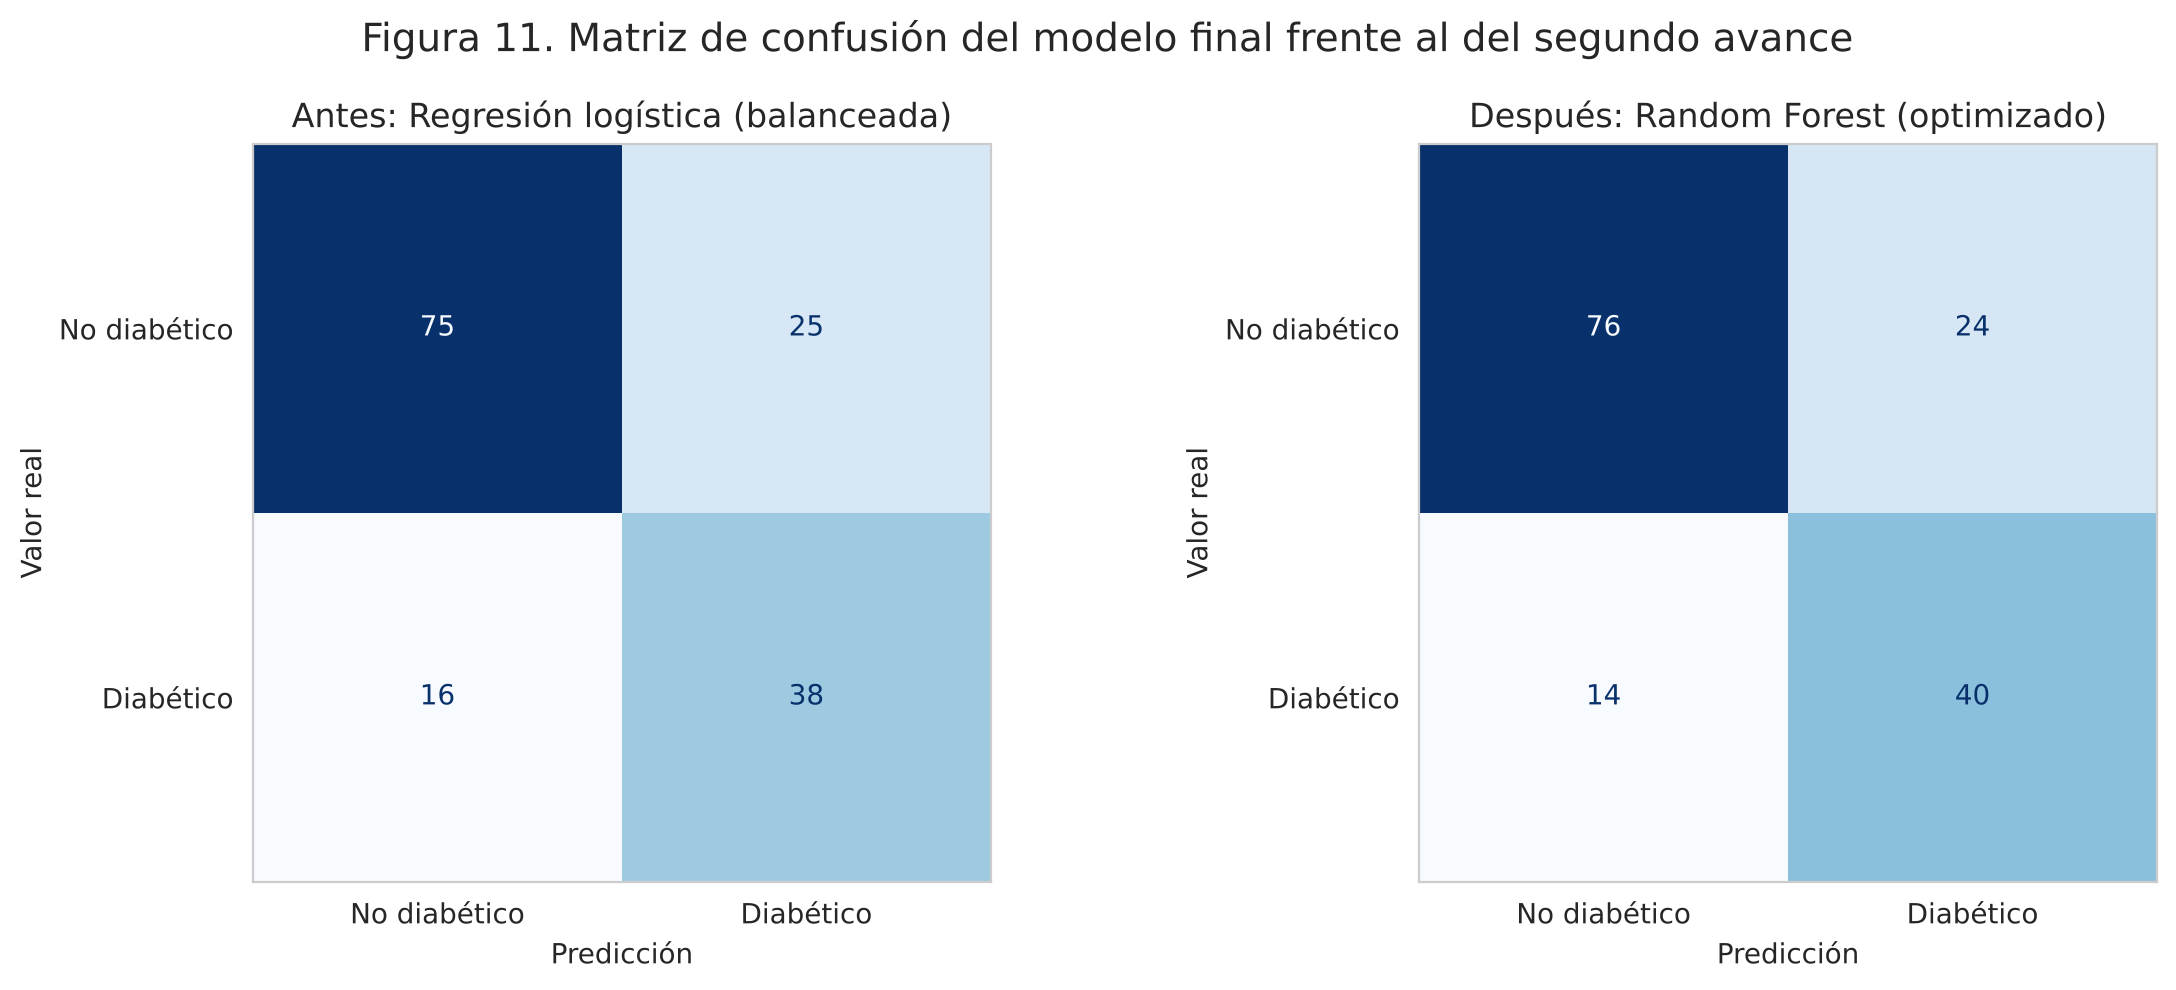

              precision    recall  f1-score   support

No diabético      0.844     0.760     0.800       100
   Diabético      0.625     0.741     0.678        54

    accuracy                          0.753       154
   macro avg      0.735     0.750     0.739       154
weighted avg      0.767     0.753     0.757       154



In [40]:
nombre_final = "Random Forest"
modelo_final = modelos_opt[nombre_final]
pred_final = modelo_final.predict(X_test_raw)
prob_final = modelo_final.predict_proba(X_test_raw)[:, 1]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (titulo, pred) in zip(axes, [("Antes: Regresión logística (balanceada)", predicciones["Regresión logística (balanceada)"]),
                                     ("Después: Random Forest (optimizado)", pred_final)]):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["No diabético", "Diabético"],
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(titulo); ax.grid(False)
    ax.set_xlabel("Predicción"); ax.set_ylabel("Valor real")
fig.suptitle("Figura 11. Matriz de confusión del modelo final frente al del segundo avance", fontsize=14)
plt.tight_layout()
plt.savefig("viz11_matriz_modelo_final.png", dpi=100)
plt.show()

print(classification_report(y_test, pred_final, target_names=["No diabético", "Diabético"], digits=3))

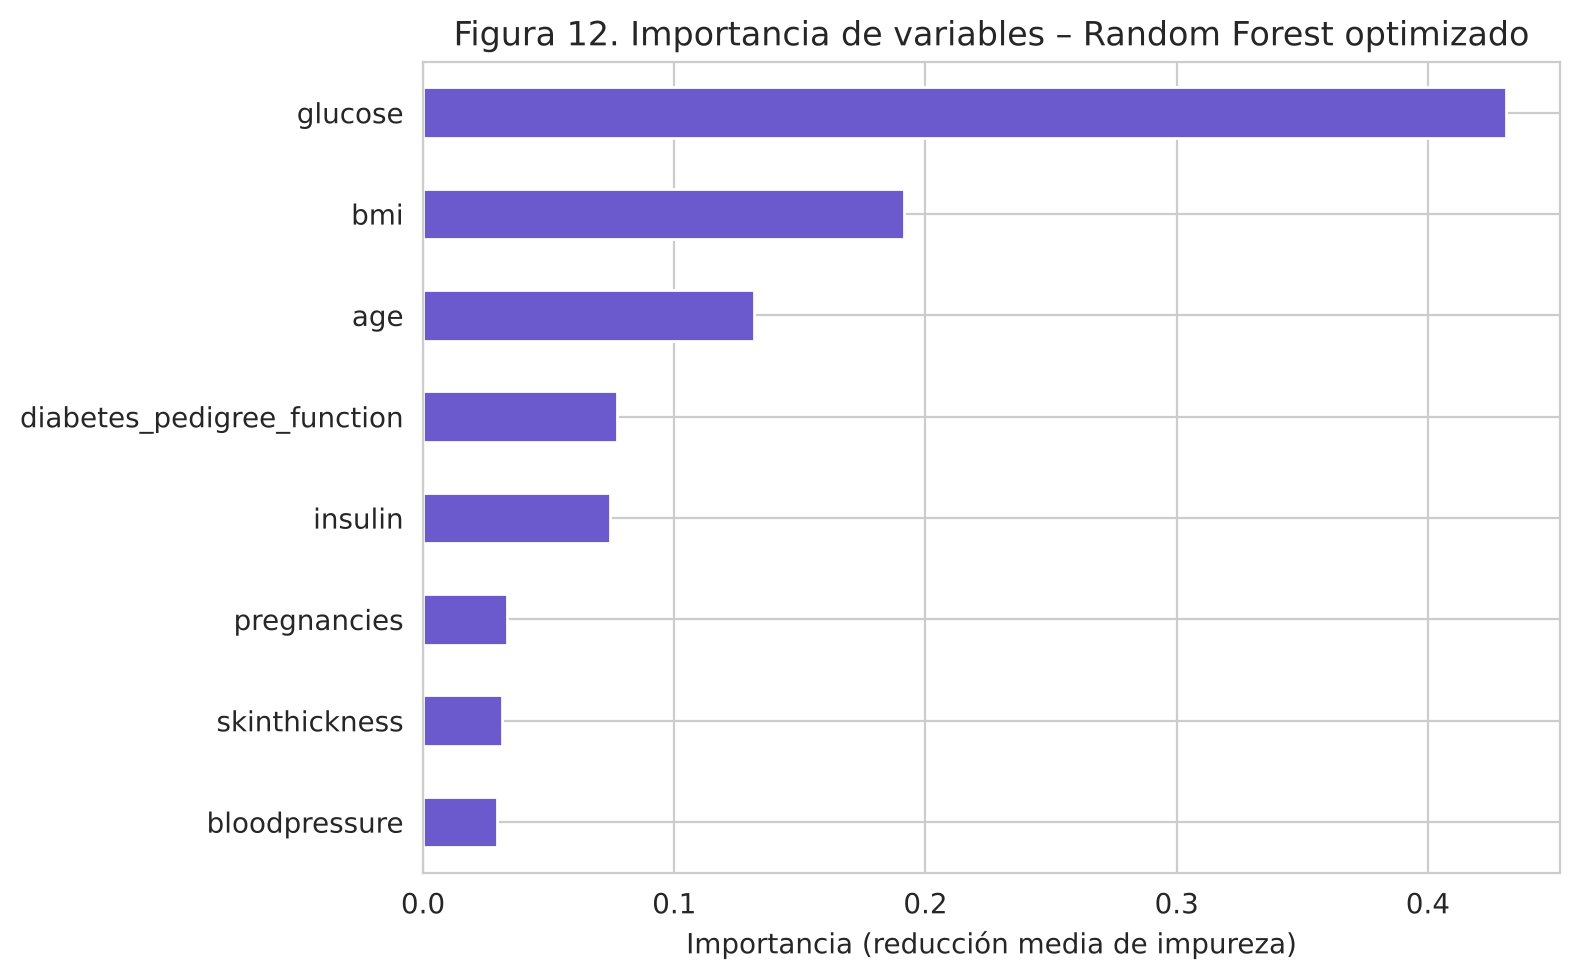

glucose                       0.431
bmi                           0.191
age                           0.132
diabetes_pedigree_function    0.077
insulin                       0.074
pregnancies                   0.033
skinthickness                 0.031
bloodpressure                 0.029
dtype: float64


In [41]:
importancias_final = pd.Series(modelo_final.named_steps["modelo"].feature_importances_,
                               index=predictoras).sort_values()
plt.figure(figsize=(8, 5))
importancias_final.plot(kind="barh", color="slateblue")
plt.title("Figura 12. Importancia de variables – Random Forest optimizado")
plt.xlabel("Importancia (reducción media de impureza)")
plt.tight_layout()
plt.savefig("viz12_importancia_modelo_final.png", dpi=100)
plt.show()
print(importancias_final.sort_values(ascending=False).round(3))

**Interpretación (Figuras 11 y 12):** el modelo final detecta 40 de las 54 diabéticas (antes 38) y clasifica bien 76 de las 100 no diabéticas (antes 75). Para la clase "No diabético" mantiene un recall de 0.76 y una precision de 0.84. La glucosa sigue siendo la variable más influyente, seguida del IMC y la edad, en línea con el EDA y con los modelos del segundo avance.

### 15.6 Guardado del pipeline final

Se guarda con `joblib` el pipeline completo (preprocesamiento + Random Forest), ya entrenado. La aplicación lo carga y no vuelve a entrenar. Junto al modelo se guardan:
- `modelo/metricas.json`: métricas finales, validación cruzada, matriz de confusión, comparación antes/después, medianas de imputación y rangos de entrenamiento;
- `modelo/registros_prueba.csv`: los 154 registros de prueba con la predicción y la probabilidad obtenidas en este notebook, para verificar que la aplicación da el mismo resultado.

**Importante:** el archivo `.joblib` debe cargarse con la misma versión de scikit-learn con la que se creó; esa versión queda registrada en `metricas.json` y fijada en `requirements.txt`.

In [42]:
import os, json, joblib, sklearn

os.makedirs("modelo", exist_ok=True)
joblib.dump(modelo_final, "modelo/pipeline_diabetes.joblib", compress=3)

def media_std(gs, metrica):
    i = gs.best_index_
    return {"media": round(float(gs.cv_results_["mean_test_" + metrica][i]), 4),
            "std": round(float(gs.cv_results_["std_test_" + metrica][i]), 4)}

prep = modelo_final.named_steps["preprocesamiento"]
medianas = dict(zip(["pregnancies"], prep.named_transformers_["embarazos"].statistics_))
medianas.update(zip(cols_fix, prep.named_transformers_["clinicas"].named_steps["ceros_a_mediana"].statistics_))
medianas.update(zip(["diabetes_pedigree_function", "age"], prep.named_transformers_["otras"].statistics_))

rangos = {}
for col in predictoras:
    valores = X_train_raw[col]
    if col in cols_fix:
        valores = valores[valores > 0]
    rangos[col] = {"min": float(valores.min()), "max": float(valores.max())}

tn, fp, fn, tp = confusion_matrix(y_test, pred_final).ravel()
reporte = classification_report(y_test, pred_final, target_names=["No diabético", "Diabético"], output_dict=True)
gs_final = busquedas_resultado[nombre_final]

metricas_finales = {
    "modelo": "Random Forest optimizado",
    "hiperparametros": {k.replace("modelo__", ""): v for k, v in gs_final.best_params_.items()} | {"n_estimators": 300},
    "version_sklearn": sklearn.__version__,
    "variables": predictoras,
    "umbral": 0.5,
    "n_entrenamiento": int(len(X_train_raw)),
    "n_prueba": int(len(X_test_raw)),
    "accuracy_entrenamiento": round(float(accuracy_score(y_train, modelo_final.predict(X_train_raw))), 4),
    "prueba": {
        "accuracy": round(float(accuracy_score(y_test, pred_final)), 4),
        "precision": round(float(precision_score(y_test, pred_final)), 4),
        "recall": round(float(recall_score(y_test, pred_final)), 4),
        "f1": round(float(f1_score(y_test, pred_final)), 4),
        "roc_auc": round(float(roc_auc_score(y_test, prob_final)), 4),
        "matriz_confusion": {"VN": int(tn), "FP": int(fp), "FN": int(fn), "VP": int(tp)},
        "por_clase": {clase: {k: round(float(v), 4) for k, v in reporte[clase].items()}
                      for clase in ["No diabético", "Diabético"]},
    },
    "validacion_cruzada": {m: media_std(gs_final, m) for m in metricas_cv},
    "comparacion": tabla_comparacion.reset_index().to_dict(orient="records"),
    "medianas_imputacion": {k: float(v) for k, v in medianas.items()},
    "rangos_entrenamiento": rangos,
    "importancias": {k: round(float(v), 4) for k, v in importancias_final.items()},
}
with open("modelo/metricas.json", "w", encoding="utf-8") as f:
    json.dump(metricas_finales, f, ensure_ascii=False, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))

registros_prueba = X_test_raw.copy()
registros_prueba.insert(0, "fila_dataset", registros_prueba.index)
registros_prueba["outcome"] = y_test.values
registros_prueba["prediccion_notebook"] = pred_final
registros_prueba["probabilidad_notebook"] = prob_final.round(6)
registros_prueba.to_csv("modelo/registros_prueba.csv", index=False)

for archivo in ["pipeline_diabetes.joblib", "metricas.json", "registros_prueba.csv"]:
    print(f"modelo/{archivo}: {os.path.getsize('modelo/' + archivo) / 1024:.1f} KB")
print("Versión de scikit-learn:", sklearn.__version__)

modelo/pipeline_diabetes.joblib: 314.9 KB
modelo/metricas.json: 4.4 KB
modelo/registros_prueba.csv: 6.9 KB
Versión de scikit-learn: 1.9.1


### 15.7 Comprobación del pipeline guardado

Se carga el archivo `.joblib` como lo hace la aplicación y se prueba con tres casos: un caso normal, un caso con datos no disponibles (insulina y pliegue cutáneo vacíos) y un registro conocido del conjunto de prueba. Las entradas inválidas (por ejemplo, edad menor de 21 años o glucosa de 0) se rechazan en la validación de la aplicación antes de llegar al modelo.

In [43]:
pipeline_cargado = joblib.load("modelo/pipeline_diabetes.joblib")
print("Predicciones del .joblib iguales a las del modelo en memoria (154 registros):",
      np.array_equal(pipeline_cargado.predict(X_test_raw), pred_final))

fila_vp = X_test_raw.index[(y_test.values == 1) & (pred_final == 1)][0]   # diabética detectada
fila_fp = X_test_raw.index[(y_test.values == 0) & (pred_final == 1)][0]   # falsa alarma
casos = pd.DataFrame([
    {"Caso": "Caso normal", "pregnancies": 2, "glucose": 110, "bloodpressure": 70, "skinthickness": 25,
     "insulin": 100, "bmi": 27.5, "diabetes_pedigree_function": 0.35, "age": 30},
    {"Caso": "Datos no disponibles", "pregnancies": 5, "glucose": 165, "bloodpressure": 76, "skinthickness": np.nan,
     "insulin": np.nan, "bmi": 36.0, "diabetes_pedigree_function": 0.60, "age": 45},
    {"Caso": f"Registro de prueba (fila {fila_vp})", **X_test_raw.loc[fila_vp].to_dict()},
    {"Caso": f"Registro de prueba (fila {fila_fp})", **X_test_raw.loc[fila_fp].to_dict()},
]).set_index("Caso")
casos["Predicción"] = pipeline_cargado.predict(casos[predictoras])
casos["Probabilidad de diabetes"] = pipeline_cargado.predict_proba(casos[predictoras])[:, 1].round(3)
casos["Valor real"] = ["–", "–", int(y_test.loc[fila_vp]), int(y_test.loc[fila_fp])]
casos

Predicciones del .joblib iguales a las del modelo en memoria (154 registros): True


,pregnancies,glucose,bloodpressure,skinthickness,insulin,bmi,diabetes_pedigree_function,age,Predicción,Probabilidad de diabetes,Valor real
Caso,,,,,,,,,,,
Caso normal,2.0,110.0,70.0,25.0,100.0,27.5,0.350,30.0,0,0.267,–
Datos no disponibles,5.0,165.0,76.0,NaN,NaN,36.0,0.600,45.0,1,0.918,–
Registro de prueba (fila 408),8.0,197.0,74.0,0.0,0.0,25.9,1.191,39.0,1,0.725,1
Registro de prueba (fila 44),7.0,159.0,64.0,0.0,0.0,27.4,0.294,40.0,1,0.732,0


**Interpretación:** el pipeline cargado reproduce las 154 predicciones del notebook y acepta campos vacíos, que imputa con la mediana del entrenamiento. De los dos registros de prueba, el primero es una paciente diabética detectada correctamente y el segundo una falsa alarma: una paciente no diabética con glucosa alta (159 mg/dL) que el modelo clasifica como diabética. Los mismos casos se probaron en la aplicación de Streamlit y dieron la misma predicción y probabilidad (ver README).

## 16. Conclusiones del tercer corte

- La revisión con la ficha técnica no encontró fuga de información ni colinealidad (VIF máximo 1.60). Los problemas detectados fueron el sobreajuste de los modelos de árboles, los hiperparámetros por defecto y una parte del preprocesamiento fuera del pipeline.
- La optimización con `GridSearchCV` y pesos de clase mejoró la detección de la clase diabética. El **Random Forest optimizado** es el modelo final: recall de 0.741 y F1 de 0.678 en prueba (0.766 y 0.704 en validación cruzada), con 14 de 54 diabéticas sin detectar frente a 16 del modelo del segundo avance.
- El pipeline completo (preprocesamiento + modelo) se guardó con `joblib` y se integró en una aplicación de Streamlit que no reentrena el modelo.

**Limitaciones que se mantienen:** aún se pierde cerca de 1 de cada 4 pacientes diabéticas; el conjunto de prueba es pequeño (154 registros); casi la mitad de los valores de insulina fueron imputados; y el dataset solo incluye mujeres de ascendencia Pima de 21 años o más, por lo que los resultados no se pueden generalizar a otras poblaciones. La aplicación es un prototipo académico y no sustituye una evaluación médica.

## 17. Declaración y evaluación del uso de inteligencia artificial – Avance 3

| Elemento | Información |
|---|---|
| **Herramienta utilizada** | Claude (Anthropic). |
| **Propósito** | Revisar el pipeline del segundo avance, proponer la optimización de hiperparámetros, generar el código para guardar el pipeline con `joblib` y construir la aplicación de Streamlit (`app.py`), `requirements.txt` y `README.md`. |
| **Prompt principal** | *"Con base en el notebook del segundo avance (Proyecto_Diabetes_Avance2.ipynb), el dataset y el enunciado de la Actividad 1 del tercer corte, revisa el rendimiento del modelo, optimízalo si es necesario registrando el antes y el después, guarda el pipeline completo con joblib y construye la aplicación de Streamlit con app.py, requirements.txt y README.md para publicarla en GitHub y Streamlit Community Cloud."* |
| **Verificación** | Se re‑ejecutó el notebook completo y se comprobó que las métricas del segundo avance se reproducen; se verificó que el nuevo preprocesamiento da las mismas predicciones que el anterior; se comprobó que el `.joblib` cargado reproduce las 154 predicciones de prueba; y se probó la aplicación con un caso normal, entradas inválidas y registros conocidos del conjunto de prueba. |
| **Problemas encontrados** | (1) La conversión de ceros a faltantes estaba fuera del pipeline, por lo que la aplicación habría tenido que repetirla. (2) Los límites de los campos numéricos de Streamlit no bastan como validación: no explican por qué un valor se rechaza. (3) Un `.joblib` creado con una versión de scikit-learn puede fallar con otra. |
| **Ajustes realizados** | Se movió todo el preprocesamiento al pipeline; se añadió una validación explícita con mensajes de error y advertencias; se fijaron las versiones en `requirements.txt`; y se seleccionó el modelo final por F1 y recall en validación cruzada, no por accuracy. |

> **Declaración de responsabilidad:** como integrantes del grupo declaramos que revisamos y verificamos el contenido generado con apoyo de herramientas de inteligencia artificial, que comprendemos el código entregado (notebook y aplicación) y que asumimos la responsabilidad académica por la totalidad del trabajo.